In [1]:
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import geopandas as gpd
import folium

from shapely.geometry import Point, LineString
from pyproj import Transformer
from scipy.spatial import cKDTree

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import os

print("Files available in Colab:\n")

for filename in os.listdir("/content"):
    print(filename)

Files available in Colab:

.config
sample_data


In [3]:
from google.colab import files

uploaded = files.upload()

Saving Student folder.zip to Student folder.zip
Saving PathSnap_student_materials.zip to PathSnap_student_materials.zip


In [4]:
import zipfile

for filename in os.listdir("/content"):
    if filename.endswith(".zip"):
        print(filename, ":", zipfile.is_zipfile(os.path.join("/content", filename)))

PathSnap_student_materials.zip : True
Student folder.zip : True


In [5]:
import os
import zipfile

with zipfile.ZipFile("/content/Student folder.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

with zipfile.ZipFile("/content/PathSnap_student_materials.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

print("Both ZIP files extracted successfully!")

Both ZIP files extracted successfully!


In [6]:
print("Contents of /content:\n")

for item in os.listdir("/content"):
    print(item)

Contents of /content:

.config
Deliverables.pdf
Assessment and Plagiarism Policy.pdf
PathSnap_student_materials.zip
Main Guidelines.pdf
Student folder
Student folder.zip
Dataset Exploration.pdf
Models and Training Guidelines.pdf
sample_data


In [7]:
import os

BASE_PATH = "/content/Student folder"

print("Main dataset folder contents:\n")

for root, dirs, files_list in os.walk(BASE_PATH):
    level = root.replace(BASE_PATH, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for filename in files_list[:10]:
        print(f"{indent}    {filename}")

    if level >= 2:
        dirs[:] = []

Main dataset folder contents:

Student folder/
    train/
        00000002/
            00000002.nodes
            00000002.track
            00000002.route
            00000002.arcs
        00000001/
            00000001.arcs
            00000001.nodes
            00000001.route
            00000001.track
        00000018/
            00000018.arcs
            00000018.nodes
            00000018.route
            00000018.track
        00000064/
            00000064.nodes
            00000064.route
            00000064.arcs
            00000064.track
        00000047/
            00000047.track
            00000047.nodes
            00000047.route
            00000047.arcs
        00000022/
            00000022.nodes
            00000022.route
            00000022.track
            00000022.arcs
        00000013/
            00000013.arcs
            00000013.track
            00000013.route
            00000013.nodes
        00000033/
            00000033.track
            00000033.a

In [8]:
import os
import pandas as pd

BASE_PATH = "/content/Student folder"

def get_inventory(partition):
    folder = os.path.join(BASE_PATH, partition)
    records = []

    for trip_id in sorted(os.listdir(folder)):
        trip_path = os.path.join(folder, trip_id)

        if not os.path.isdir(trip_path):
            continue

        record = {"Trip_ID": trip_id}

        for extension in [".nodes", ".track", ".route", ".arcs"]:
            filepath = os.path.join(trip_path, trip_id + extension)

            if os.path.exists(filepath):
                with open(filepath, "r") as f:
                    record[extension[1:].upper() + "_Rows"] = sum(
                        1 for line in f if line.strip()
                    )
                record[extension[1:].upper() + "_Size_KB"] = round(
                    os.path.getsize(filepath) / 1024, 2
                )
            else:
                record[extension[1:].upper() + "_Rows"] = 0
                record[extension[1:].upper() + "_Size_KB"] = 0

        records.append(record)

    return pd.DataFrame(records)


train_inventory = get_inventory("train")
test_inventory = get_inventory("student_test")

print("TRAINING DATA INVENTORY")
display(train_inventory)

print("STUDENT TEST DATA INVENTORY")
display(test_inventory)

print("Total training trips:", len(train_inventory))
print("Total student-test trips:", len(test_inventory))

TRAINING DATA INVENTORY


,Trip_ID,NODES_Rows,NODES_Size_KB,TRACK_Rows,TRACK_Size_KB,ROUTE_Rows,ROUTE_Size_KB,ARCS_Rows,ARCS_Size_KB
0,00000001,88809,1647.82,1315,40.01,525,3.05,165790,1902.81
1,00000002,7936,155.00,7243,232.50,262,1.37,16139,152.85
2,00000003,9138,178.48,821,25.55,79,0.40,18028,171.61
3,00000004,7350,143.55,1064,34.16,320,1.54,15499,146.23
4,00000005,898,17.54,1045,32.60,105,0.41,1579,12.06
...,...,...,...,...,...,...,...,...,...
75,00000095,1888,36.88,1551,48.91,306,1.36,3723,31.91
76,00000096,16893,346.44,3271,107.53,456,2.63,32276,333.15
77,00000097,23566,460.27,1740,55.00,444,2.33,48503,522.36
78,00000098,43440,933.28,5584,189.93,1003,5.70,88137,989.04


STUDENT TEST DATA INVENTORY


,Trip_ID,NODES_Rows,NODES_Size_KB,TRACK_Rows,TRACK_Size_KB,ROUTE_Rows,ROUTE_Size_KB,ARCS_Rows,ARCS_Size_KB
0,00000000,8542,166.84,2503,79.58,179,0.86,18196,172.84
1,00000007,2061,40.25,1354,42.55,123,0.47,4369,38.08
2,00000009,6745,131.74,1049,32.73,429,2.17,13106,123.72
3,00000040,12945,252.83,2995,95.44,309,1.47,27026,271.41
4,00000052,1770,34.57,262,8.08,95,0.46,3577,30.18
5,00000056,14759,302.67,3958,130.35,1323,7.45,27631,281.29
6,00000065,6448,125.94,768,23.94,145,0.68,13184,125.02
7,00000076,26635,520.21,1486,47.26,374,2.05,56027,609.61
8,00000077,4424,86.41,3911,124.96,268,1.23,9622,88.92
9,00000091,6360,118.01,874,26.35,232,1.07,12303,116.48


Total training trips: 80
Total student-test trips: 10


In [9]:
import os
import pandas as pd

BASE_PATH = "/content/Student folder"

train_folder = os.path.join(BASE_PATH, "train")
trip_id = sorted(os.listdir(train_folder))[0]

track_file = os.path.join(
    train_folder, trip_id, trip_id + ".track"
)

print("Track file:", track_file)

with open(track_file, "r") as f:
    for i in range(10):
        line = f.readline()
        if not line:
            break
        print(line.rstrip())

Track file: /content/Student folder/train/00000001/00000001.track
8.595203	49.844053	1.000000
8.595294	49.844441	2.000000
8.595352	49.844883	3.000000
8.595390	49.845379	4.000000
8.595587	49.845750	5.000000
8.595555	49.846167	6.000000
8.595744	49.846565	7.000000
8.595733	49.846931	8.000000
8.595878	49.847374	9.000000
8.595849	49.847684	10.000000


In [10]:
import os
import pandas as pd
import numpy as np

BASE_PATH = "/content/Student folder"

def load_track(filepath):
    return pd.read_csv(
        filepath,
        sep="\t",
        header=None,
        names=["longitude", "latitude", "timestamp"]
    )

def check_gps_quality(partition):
    folder = os.path.join(BASE_PATH, partition)
    results = []

    for trip_id in sorted(os.listdir(folder)):
        trip_path = os.path.join(folder, trip_id)

        if not os.path.isdir(trip_path):
            continue

        filepath = os.path.join(
            trip_path, trip_id + ".track"
        )

        if not os.path.exists(filepath):
            continue

        df = load_track(filepath)

        results.append({
            "Trip_ID": trip_id,
            "Total_Points": len(df),
            "Missing_Values": df.isnull().sum().sum(),
            "Invalid_Longitude": (~df["longitude"].between(-180, 180)).sum(),
            "Invalid_Latitude": (~df["latitude"].between(-90, 90)).sum(),
            "Zero_Coordinates": (
                (df["longitude"] == 0) &
                (df["latitude"] == 0)
            ).sum(),
            "Duplicate_Points": df.duplicated(
                subset=["longitude", "latitude", "timestamp"]
            ).sum()
        })

    return pd.DataFrame(results)


train_quality = check_gps_quality("train")
test_quality = check_gps_quality("student_test")

print("TRAINING GPS QUALITY")
display(train_quality)

print("STUDENT TEST GPS QUALITY")
display(test_quality)

print("\nTRAINING TOTALS")
display(train_quality.drop(columns=["Trip_ID"]).sum())

print("\nSTUDENT TEST TOTALS")
display(test_quality.drop(columns=["Trip_ID"]).sum())

TRAINING GPS QUALITY


,Trip_ID,Total_Points,Missing_Values,Invalid_Longitude,Invalid_Latitude,Zero_Coordinates,Duplicate_Points
0,00000001,1315,0,0,0,0,0
1,00000002,7243,0,0,0,0,0
2,00000003,821,0,0,0,0,0
3,00000004,1064,0,0,0,0,0
4,00000005,1045,0,0,0,0,0
...,...,...,...,...,...,...,...
75,00000095,1551,0,0,0,0,0
76,00000096,3271,0,0,0,0,0
77,00000097,1740,0,0,0,0,0
78,00000098,5584,0,0,0,0,0


STUDENT TEST GPS QUALITY


,Trip_ID,Total_Points,Missing_Values,Invalid_Longitude,Invalid_Latitude,Zero_Coordinates,Duplicate_Points
0,00000000,2503,0,0,0,0,0
1,00000007,1354,0,0,0,0,0
2,00000009,1049,0,0,0,0,0
3,00000040,2995,0,0,0,0,0
4,00000052,262,0,0,0,0,0
5,00000056,3958,0,0,0,0,0
6,00000065,768,0,0,0,0,0
7,00000076,1486,0,0,0,0,0
8,00000077,3911,0,0,0,0,0
9,00000091,874,0,0,0,0,0



TRAINING TOTALS


,0
Total_Points,208417
Missing_Values,0
Invalid_Longitude,0
Invalid_Latitude,0
Zero_Coordinates,0
Duplicate_Points,0



STUDENT TEST TOTALS


,0
Total_Points,19160
Missing_Values,0
Invalid_Longitude,0
Invalid_Latitude,0
Zero_Coordinates,0
Duplicate_Points,0


In [11]:
import os
import pandas as pd
import numpy as np

BASE_PATH = "/content/Student folder"

def analyse_timestamps(partition):
    folder = os.path.join(BASE_PATH, partition)
    results = []

    for trip_id in sorted(os.listdir(folder)):
        trip_path = os.path.join(folder, trip_id)

        if not os.path.isdir(trip_path):
            continue

        filepath = os.path.join(
            trip_path, trip_id + ".track"
        )

        if not os.path.exists(filepath):
            continue

        df = load_track(filepath)

        timestamps = pd.to_numeric(
            df["timestamp"], errors="coerce"
        ).dropna()

        differences = timestamps.diff().dropna()

        results.append({
            "Trip_ID": trip_id,
            "GPS_Points": len(df),
            "Median_Interval": differences.median(),
            "Mean_Interval": differences.mean(),
            "Intervals_1_Second": (differences == 1).sum(),
            "Intervals_Above_5_Seconds": (differences > 5).sum(),
            "Maximum_Gap": differences.max()
        })

    return pd.DataFrame(results)


train_time = analyse_timestamps("train")
test_time = analyse_timestamps("student_test")

print("TRAINING TIMESTAMP ANALYSIS")
display(train_time)

print("STUDENT TEST TIMESTAMP ANALYSIS")
display(test_time)

print("\nTRAINING SUMMARY")
display(train_time.drop(columns=["Trip_ID"]).describe())

print("\nSTUDENT TEST SUMMARY")
display(test_time.drop(columns=["Trip_ID"]).describe())

TRAINING TIMESTAMP ANALYSIS


,Trip_ID,GPS_Points,Median_Interval,Mean_Interval,Intervals_1_Second,Intervals_Above_5_Seconds,Maximum_Gap
0,00000001,1315,1.0,1.032725,1289,1,16.0
1,00000002,7243,1.0,1.233521,7057,78,160.0
2,00000003,821,1.0,1.003659,817,0,2.0
3,00000004,1064,1.0,4.907808,572,320,51.0
4,00000005,1045,1.0,1.000000,1044,0,1.0
...,...,...,...,...,...,...,...
75,00000095,1551,1.0,1.003226,1545,0,2.0
76,00000096,3271,1.0,1.000000,3270,0,1.0
77,00000097,1740,1.0,1.006902,1723,0,2.0
78,00000098,5584,1.0,1.288555,4315,13,50.0


STUDENT TEST TIMESTAMP ANALYSIS


,Trip_ID,GPS_Points,Median_Interval,Mean_Interval,Intervals_1_Second,Intervals_Above_5_Seconds,Maximum_Gap
0,00000000,2503,1.0,1.000400,2501,0,2.0
1,00000007,1354,1.0,1.000000,1353,0,1.0
2,00000009,1049,1.0,1.000954,1047,0,2.0
3,00000040,2995,1.0,1.000000,2994,0,1.0
4,00000052,262,1.0,1.015326,257,0,2.0
5,00000056,3958,1.0,1.010867,3916,0,3.0
6,00000065,768,1.0,1.352021,756,5,210.0
7,00000076,1486,1.0,1.525926,1279,39,32.0
8,00000077,3911,1.0,1.000000,3910,0,1.0
9,00000091,874,1.0,1.000000,873,0,1.0



TRAINING SUMMARY


,GPS_Points,Median_Interval,Mean_Interval,Intervals_1_Second,Intervals_Above_5_Seconds,Maximum_Gap
count,80.000000,80.0,80.000000,80.000000,80.000000,80.000000
mean,2605.212500,1.0,5.101888,2513.100000,15.200000,2706.400000
std,3312.345399,0.0,32.091673,3304.947299,42.350676,18017.445084
min,361.000000,1.0,1.000000,211.000000,0.000000,1.000000
25%,945.750000,1.0,1.000243,817.000000,0.000000,1.750000
50%,1529.000000,1.0,1.058959,1525.500000,1.000000,11.000000
75%,2792.750000,1.0,1.293029,2524.250000,11.250000,73.750000
max,19313.000000,1.0,287.906542,19282.000000,320.000000,153064.000000



STUDENT TEST SUMMARY


,GPS_Points,Median_Interval,Mean_Interval,Intervals_1_Second,Intervals_Above_5_Seconds,Maximum_Gap
count,10.000000,10.0,10.000000,10.00000,10.000000,10.000000
mean,1916.000000,1.0,1.090549,1888.60000,4.400000,25.500000
std,1335.432348,0.0,0.188231,1339.00736,12.258331,65.529044
min,262.000000,1.0,1.000000,257.00000,0.000000,1.000000
25%,917.750000,1.0,1.000000,916.50000,0.000000,1.000000
50%,1420.000000,1.0,1.000677,1316.00000,0.000000,2.000000
75%,2872.000000,1.0,1.014211,2870.75000,0.000000,2.750000
max,3958.000000,1.0,1.525926,3916.00000,39.000000,210.000000


In [12]:
print("TOP 10 TRAINING TRIPS WITH LARGEST TIMESTAMP GAPS")

display(
    train_time.sort_values(
        by="Maximum_Gap",
        ascending=False
    ).head(10)
)

print("TOP 5 STUDENT-TEST TRIPS WITH LARGEST TIMESTAMP GAPS")

display(
    test_time.sort_values(
        by="Maximum_Gap",
        ascending=False
    ).head(5)
)

TOP 10 TRAINING TRIPS WITH LARGEST TIMESTAMP GAPS


,Trip_ID,GPS_Points,Median_Interval,Mean_Interval,Intervals_1_Second,Intervals_Above_5_Seconds,Maximum_Gap
72,00000090,536,1.0,287.906542,311,20,153064.0
61,00000078,2909,1.0,19.888583,2196,124,52810.0
55,00000069,2067,1.0,2.690223,2044,2,2658.0
16,00000021,15783,1.0,1.178875,15776,2,2161.0
8,00000011,2828,1.0,1.321189,2826,1,909.0
34,00000042,7739,1.0,1.599509,7657,45,670.0
64,00000081,3224,1.0,2.631399,2320,129,536.0
18,00000024,801,1.0,1.926250,777,4,458.0
36,00000044,546,1.0,1.798165,491,2,341.0
67,00000084,16031,1.0,1.030817,15980,4,312.0


TOP 5 STUDENT-TEST TRIPS WITH LARGEST TIMESTAMP GAPS


,Trip_ID,GPS_Points,Median_Interval,Mean_Interval,Intervals_1_Second,Intervals_Above_5_Seconds,Maximum_Gap
6,00000065,768,1.0,1.352021,756,5,210.0
7,00000076,1486,1.0,1.525926,1279,39,32.0
5,00000056,3958,1.0,1.010867,3916,0,3.0
0,00000000,2503,1.0,1.000400,2501,0,2.0
4,00000052,262,1.0,1.015326,257,0,2.0


In [13]:
BASE_PATH = "/content/Student folder"
trip_id = "00000001"

trip_path = os.path.join(BASE_PATH, "train", trip_id)

for extension in [".nodes", ".arcs", ".route"]:
    filepath = os.path.join(
        trip_path, trip_id + extension
    )

    print("\n" + "=" * 50)
    print("FILE:", extension)
    print("=" * 50)

    with open(filepath, "r") as f:
        for i in range(5):
            line = f.readline()
            if not line:
                break
            print(line.rstrip())


FILE: .nodes
8.581679	49.857880
8.584637	49.858295
8.580173	49.858567
8.584392	49.859119
8.584935	49.857396

FILE: .arcs
0	281
0	1
0	5
1	0
1	40750

FILE: .route
2641
64973
133948
133949
139208


In [14]:
import os
import pandas as pd
import networkx as nx

BASE_PATH = "/content/Student folder"
trip_id = "00000001"

trip_path = os.path.join(BASE_PATH, "train", trip_id)

nodes = pd.read_csv(
    os.path.join(trip_path, trip_id + ".nodes"),
    sep=r"\s+",
    header=None,
    names=["longitude", "latitude"]
)

arcs = pd.read_csv(
    os.path.join(trip_path, trip_id + ".arcs"),
    sep=r"\s+",
    header=None,
    names=["from_node", "to_node"]
)

route = pd.read_csv(
    os.path.join(trip_path, trip_id + ".route"),
    header=None,
    names=["arc_id"]
)

invalid_endpoints = (
    (arcs["from_node"] < 0) |
    (arcs["to_node"] < 0) |
    (arcs["from_node"] >= len(nodes)) |
    (arcs["to_node"] >= len(nodes))
)

invalid_route_ids = (
    (route["arc_id"] < 0) |
    (route["arc_id"] >= len(arcs))
)

print("ROAD NETWORK VALIDATION")
print("-----------------------")
print("Number of nodes:", len(nodes))
print("Number of arcs:", len(arcs))
print("Number of route entries:", len(route))
print("Invalid arc endpoints:", invalid_endpoints.sum())
print("Invalid route IDs:", invalid_route_ids.sum())
print("Self-loop arcs:", (arcs["from_node"] == arcs["to_node"]).sum())
print("Duplicate directed arcs:", arcs.duplicated().sum())

G_directed = nx.DiGraph()
G_directed.add_nodes_from(range(len(nodes)))
G_directed.add_edges_from(
    arcs[["from_node", "to_node"]].itertuples(
        index=False, name=None
    )
)

G_undirected = G_directed.to_undirected()

print("\nCONNECTIVITY")
print("------------")
print("Directed nodes:", G_directed.number_of_nodes())
print("Directed edges:", G_directed.number_of_edges())
print("Weakly connected components:",
      nx.number_weakly_connected_components(G_directed))
print("Strongly connected components:",
      nx.number_strongly_connected_components(G_directed))
print("Undirected connected components:",
      nx.number_connected_components(G_undirected))
print("Isolated nodes:",
      len(list(nx.isolates(G_undirected))))

ROAD NETWORK VALIDATION
-----------------------
Number of nodes: 88809
Number of arcs: 165790
Number of route entries: 525
Invalid arc endpoints: 0
Invalid route IDs: 0
Self-loop arcs: 0
Duplicate directed arcs: 292

CONNECTIVITY
------------
Directed nodes: 88809
Directed edges: 165498
Weakly connected components: 175
Strongly connected components: 1942
Undirected connected components: 175
Isolated nodes: 0


In [15]:
import os
import pandas as pd
import numpy as np
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

BASE_PATH = "/content/Student folder"

def analyse_road_network(partition):
    folder = os.path.join(BASE_PATH, partition)
    results = []

    for trip_id in sorted(os.listdir(folder)):
        trip_path = os.path.join(folder, trip_id)

        if not os.path.isdir(trip_path):
            continue

        nodes_file = os.path.join(
            trip_path, trip_id + ".nodes"
        )
        arcs_file = os.path.join(
            trip_path, trip_id + ".arcs"
        )
        route_file = os.path.join(
            trip_path, trip_id + ".route"
        )

        if not all(os.path.exists(f) for f in
                   [nodes_file, arcs_file, route_file]):
            continue

        nodes = pd.read_csv(
            nodes_file, sep=r"\s+", header=None
        )

        arcs = pd.read_csv(
            arcs_file,
            sep=r"\s+",
            header=None,
            names=["from_node", "to_node"]
        )

        route = pd.read_csv(
            route_file,
            header=None,
            names=["arc_id"]
        )

        n = len(nodes)

        invalid_endpoints = (
            (arcs["from_node"] < 0) |
            (arcs["to_node"] < 0) |
            (arcs["from_node"] >= n) |
            (arcs["to_node"] >= n)
        )

        invalid_route = (
            (route["arc_id"] < 0) |
            (route["arc_id"] >= len(arcs))
        )

        valid_arcs = arcs.loc[~invalid_endpoints]

        adjacency = coo_matrix(
            (
                np.ones(len(valid_arcs)),
                (
                    valid_arcs["from_node"],
                    valid_arcs["to_node"]
                )
            ),
            shape=(n, n)
        ).tocsr()

        weak_count = connected_components(
            adjacency,
            directed=True,
            connection="weak",
            return_labels=False
        )

        strong_count = connected_components(
            adjacency,
            directed=True,
            connection="strong",
            return_labels=False
        )

        connected_nodes = np.unique(
            np.concatenate([
                valid_arcs["from_node"].to_numpy(),
                valid_arcs["to_node"].to_numpy()
            ])
        )

        isolated_nodes = n - len(connected_nodes)

        results.append({
            "Trip_ID": trip_id,
            "Nodes": n,
            "Arc_Rows": len(arcs),
            "Route_Entries": len(route),
            "Invalid_Endpoints": int(invalid_endpoints.sum()),
            "Invalid_Route_IDs": int(invalid_route.sum()),
            "Duplicate_Arcs": int(arcs.duplicated().sum()),
            "Weak_Components": weak_count,
            "Strong_Components": strong_count,
            "Isolated_Nodes": isolated_nodes
        })

    return pd.DataFrame(results)


train_network = analyse_road_network("train")
test_network = analyse_road_network("student_test")

print("TRAINING ROAD NETWORK ANALYSIS")
display(train_network)

print("STUDENT TEST ROAD NETWORK ANALYSIS")
display(test_network)

print("\nTRAINING SUMMARY")
display(train_network.drop(columns=["Trip_ID"]).sum())

print("\nSTUDENT TEST SUMMARY")
display(test_network.drop(columns=["Trip_ID"]).sum())

TRAINING ROAD NETWORK ANALYSIS


,Trip_ID,Nodes,Arc_Rows,Route_Entries,Invalid_Endpoints,Invalid_Route_IDs,Duplicate_Arcs,Weak_Components,Strong_Components,Isolated_Nodes
0,00000001,88809,165790,525,0,0,292,175,1942,0
1,00000002,7936,16139,262,0,0,0,14,14,0
2,00000003,9138,18028,79,0,0,6,42,167,0
3,00000004,7350,15499,320,0,0,5,12,14,0
4,00000005,898,1579,105,0,0,0,3,153,0
...,...,...,...,...,...,...,...,...,...,...
75,00000095,1888,3723,306,0,0,0,7,16,0
76,00000096,16893,32276,456,0,0,3,18,325,0
77,00000097,23566,48503,444,0,0,0,27,27,0
78,00000098,43440,88137,1003,0,0,10,20,126,0


STUDENT TEST ROAD NETWORK ANALYSIS


,Trip_ID,Nodes,Arc_Rows,Route_Entries,Invalid_Endpoints,Invalid_Route_IDs,Duplicate_Arcs,Weak_Components,Strong_Components,Isolated_Nodes
0,00000000,8542,18196,179,0,0,6,100,102,0
1,00000007,2061,4369,123,0,0,0,6,6,0
2,00000009,6745,13106,429,0,0,62,8,56,0
3,00000040,12945,27026,309,0,0,0,15,39,0
4,00000052,1770,3577,95,0,0,2,7,16,0
5,00000056,14759,27631,1323,0,0,22,24,415,0
6,00000065,6448,13184,145,0,0,4,5,73,0
7,00000076,26635,56027,374,0,0,29,40,205,0
8,00000077,4424,9622,268,0,0,0,11,11,0
9,00000091,6360,12303,232,0,0,3,11,51,0



TRAINING SUMMARY


,0
Nodes,1933485
Arc_Rows,3876904
Route_Entries,31336
Invalid_Endpoints,0
Invalid_Route_IDs,0
Duplicate_Arcs,1775
Weak_Components,3121
Strong_Components,20038
Isolated_Nodes,0



STUDENT TEST SUMMARY


,0
Nodes,90689
Arc_Rows,185041
Route_Entries,3477
Invalid_Endpoints,0
Invalid_Route_IDs,0
Duplicate_Arcs,128
Weak_Components,227
Strong_Components,974
Isolated_Nodes,0


In [16]:
import os
import pandas as pd

BASE_PATH = "/content/Student folder"

def get_coordinate_bounds(partition, file_extension):
    folder = os.path.join(BASE_PATH, partition)

    all_coordinates = []

    for trip_id in sorted(os.listdir(folder)):
        trip_path = os.path.join(folder, trip_id)

        if not os.path.isdir(trip_path):
            continue

        filepath = os.path.join(
            trip_path, trip_id + file_extension
        )

        if not os.path.exists(filepath):
            continue

        data = pd.read_csv(
            filepath,
            sep=r"\s+",
            header=None
        )

        all_coordinates.append(data.iloc[:, :2])

    coordinates = pd.concat(all_coordinates, ignore_index=True)

    coordinates.columns = ["longitude", "latitude"]

    return coordinates


train_nodes = get_coordinate_bounds("train", ".nodes")
test_nodes = get_coordinate_bounds("student_test", ".nodes")

train_tracks = get_coordinate_bounds("train", ".track")
test_tracks = get_coordinate_bounds("student_test", ".track")


all_nodes = pd.concat([train_nodes, test_nodes], ignore_index=True)
all_tracks = pd.concat([train_tracks, test_tracks], ignore_index=True)

print("ROAD NODE COORDINATE BOUNDS")
display(all_nodes.agg(["min", "max"]))

print("GPS TRACK COORDINATE BOUNDS")
display(all_tracks.agg(["min", "max"]))

print("\nROAD NODE CENTRE")
print("Longitude:", all_nodes["longitude"].mean())
print("Latitude:", all_nodes["latitude"].mean())

print("\nGPS TRACK CENTRE")
print("Longitude:", all_tracks["longitude"].mean())
print("Latitude:", all_tracks["latitude"].mean())

ROAD NODE COORDINATE BOUNDS


,longitude,latitude
min,-100.428454,-34.650477
max,137.247005,61.709158


GPS TRACK COORDINATE BOUNDS


,longitude,latitude
min,-100.418538,-34.640291
max,137.237029,61.699590



ROAD NODE CENTRE
Longitude: 16.769725918407705
Latitude: 45.17381533964817

GPS TRACK CENTRE
Longitude: 15.455824556993893
Latitude: 41.46632529825949


In [17]:
import os
import numpy as np
import pandas as pd

BASE_PATH = "/content/Student folder"

def get_trip_utm_summary(partition):
    folder = os.path.join(BASE_PATH, partition)
    results = []

    for trip_id in sorted(os.listdir(folder)):
        trip_path = os.path.join(folder, trip_id)

        if not os.path.isdir(trip_path):
            continue

        nodes_file = os.path.join(trip_path, trip_id + ".nodes")
        track_file = os.path.join(trip_path, trip_id + ".track")

        nodes = pd.read_csv(
            nodes_file, sep=r"\s+", header=None,
            names=["longitude", "latitude"]
        )

        tracks = pd.read_csv(
            track_file, sep=r"\s+", header=None,
            names=["longitude", "latitude", "timestamp"]
        )

        coords = pd.concat([
            nodes[["longitude", "latitude"]],
            tracks[["longitude", "latitude"]]
        ], ignore_index=True)

        min_lon = coords["longitude"].min()
        max_lon = coords["longitude"].max()
        min_lat = coords["latitude"].min()
        max_lat = coords["latitude"].max()

        centre_lon = coords["longitude"].mean()
        centre_lat = coords["latitude"].mean()

        zone = int(np.floor((centre_lon + 180) / 6) + 1)
        zone = max(1, min(zone, 60))

        hemisphere = "N" if centre_lat >= 0 else "S"

        epsg = (32600 if hemisphere == "N" else 32700) + zone

        results.append({
            "Trip_ID": trip_id,
            "Min_Longitude": min_lon,
            "Max_Longitude": max_lon,
            "Min_Latitude": min_lat,
            "Max_Latitude": max_lat,
            "Longitude_Span": max_lon - min_lon,
            "Latitude_Span": max_lat - min_lat,
            "Centre_Longitude": centre_lon,
            "Centre_Latitude": centre_lat,
            "UTM_Zone": zone,
            "Hemisphere": hemisphere,
            "EPSG": epsg
        })

    return pd.DataFrame(results)


train_utm = get_trip_utm_summary("train")
test_utm = get_trip_utm_summary("student_test")

print("TRAINING TRIP UTM SUMMARY")
display(train_utm)

print("STUDENT TEST TRIP UTM SUMMARY")
display(test_utm)

print("\nUTM ZONES USED")
print("Training:")
display(train_utm["EPSG"].value_counts().sort_index())

print("Student test:")
display(test_utm["EPSG"].value_counts().sort_index())

print("\nTRIPS WITH LARGE LONGITUDE SPANS")
display(
    pd.concat([train_utm, test_utm])
    .sort_values("Longitude_Span", ascending=False)
    .head(10)
)

TRAINING TRIP UTM SUMMARY


,Trip_ID,Min_Longitude,Max_Longitude,Min_Latitude,Max_Latitude,Longitude_Span,Latitude_Span,Centre_Longitude,Centre_Latitude,UTM_Zone,Hemisphere,EPSG
0,00000001,8.560594,8.657860,49.833564,50.221877,0.097266,0.388313,8.612950,50.047452,32,N,32632
1,00000002,10.990111,11.060610,47.648443,47.705375,0.070499,0.056932,11.028598,47.676785,32,N,32632
2,00000003,37.144189,37.211478,55.967219,56.017514,0.067289,0.050295,37.176392,55.988371,37,N,32637
3,00000004,12.332375,12.469614,52.578302,52.728951,0.137239,0.150649,12.387626,52.630162,33,N,32633
4,00000005,35.477043,35.554415,49.348308,49.619027,0.077372,0.270719,35.508114,49.487851,36,N,32636
...,...,...,...,...,...,...,...,...,...,...,...,...
75,00000095,-1.300417,-1.258487,50.726721,50.766255,0.041930,0.039534,-1.282896,50.749868,30,N,32630
76,00000096,-95.879309,-95.322158,36.127533,36.272715,0.557151,0.145182,-95.702377,36.188324,15,N,32615
77,00000097,11.855189,12.230777,55.938797,56.068954,0.375588,0.130157,12.057508,56.000506,33,N,32633
78,00000098,-51.678981,-51.177115,-29.711584,-29.381497,0.501866,0.330087,-51.437480,-29.541994,22,S,32722


STUDENT TEST TRIP UTM SUMMARY


,Trip_ID,Min_Longitude,Max_Longitude,Min_Latitude,Max_Latitude,Longitude_Span,Latitude_Span,Centre_Longitude,Centre_Latitude,UTM_Zone,Hemisphere,EPSG
0,00000000,54.238593,54.973630,56.070572,56.264534,0.735037,0.193962,54.522018,56.147423,40,N,32640
1,00000007,77.112093,77.280906,43.378763,43.506274,0.168813,0.127511,77.197810,43.416444,43,N,32643
2,00000009,13.622095,13.716908,42.635672,42.672403,0.094813,0.036731,13.676108,42.656598,33,N,32633
3,00000040,61.059539,61.302585,55.165338,55.426294,0.243046,0.260956,61.207295,55.268419,41,N,32641
4,00000052,35.848118,35.906404,56.785271,56.837409,0.058286,0.052138,35.880930,56.819904,36,N,32636
5,00000056,-93.434290,-93.338509,44.826035,44.883353,0.095781,0.057318,-93.390303,44.855795,15,N,32615
6,00000065,49.253289,49.339762,53.502682,53.548904,0.086473,0.046222,49.298702,53.526280,39,N,32639
7,00000076,43.951486,44.043704,56.230451,56.338713,0.092218,0.108262,43.999709,56.294994,38,N,32638
8,00000077,50.779109,50.851261,61.629854,61.709158,0.072152,0.079304,50.817661,61.668026,39,N,32639
9,00000091,2.401240,2.453548,47.043230,47.109674,0.052308,0.066444,2.421390,47.081944,31,N,32631



UTM ZONES USED
Training:


,count
EPSG,
32614,1
32615,1
32616,2
32617,3
32622,1
32629,3
32630,9
32631,6
32632,8


Student test:


,count
EPSG,
32615,1
32631,1
32633,1
32636,1
32638,1
32639,2
32640,1
32641,1
32643,1



TRIPS WITH LARGE LONGITUDE SPANS


,Trip_ID,Min_Longitude,Max_Longitude,Min_Latitude,Max_Latitude,Longitude_Span,Latitude_Span,Centre_Longitude,Centre_Latitude,UTM_Zone,Hemisphere,EPSG
22,00000028,60.299915,61.423467,54.912328,55.152045,1.123552,0.239717,60.994103,55.038026,41,N,32641
25,00000032,12.388179,13.325146,51.873464,52.318882,0.936967,0.445418,12.893082,52.114542,33,N,32633
53,00000066,48.592404,49.519989,53.159726,53.408132,0.927585,0.248406,49.124487,53.281030,39,N,32639
0,00000000,54.238593,54.973630,56.070572,56.264534,0.735037,0.193962,54.522018,56.147423,40,N,32640
10,00000013,1.454339,2.147104,43.626188,43.937109,0.692765,0.310921,1.783137,43.779444,31,N,32631
61,00000078,3.576181,4.206417,44.216942,44.377330,0.630236,0.160388,3.918634,44.292847,31,N,32631
24,00000031,50.173719,50.774587,53.197572,53.483238,0.600868,0.285666,50.345368,53.317339,39,N,32639
69,00000086,60.241273,60.815561,56.770127,57.283050,0.574288,0.512923,60.578524,56.893146,41,N,32641
76,00000096,-95.879309,-95.322158,36.127533,36.272715,0.557151,0.145182,-95.702377,36.188324,15,N,32615
14,00000019,6.883770,7.392425,52.095922,52.233890,0.508655,0.137968,7.092801,52.175775,32,N,32632


In [18]:
import os
import pandas as pd
import numpy as np
from pyproj import Transformer

BASE_PATH = "/content/Student folder"

projected_data = {
    "train": {},
    "student_test": {}
}

def project_partition(partition, utm_summary):

    folder = os.path.join(BASE_PATH, partition)

    for _, row in utm_summary.iterrows():

        trip_id = row["Trip_ID"]
        epsg = int(row["EPSG"])

        trip_path = os.path.join(folder, trip_id)

        nodes = pd.read_csv(
            os.path.join(trip_path, trip_id + ".nodes"),
            sep=r"\s+",
            header=None,
            names=["longitude", "latitude"]
        )

        track = pd.read_csv(
            os.path.join(trip_path, trip_id + ".track"),
            sep=r"\s+",
            header=None,
            names=["longitude", "latitude", "timestamp"]
        )

        arcs = pd.read_csv(
            os.path.join(trip_path, trip_id + ".arcs"),
            sep=r"\s+",
            header=None,
            names=["from_node", "to_node"]
        )

        route = pd.read_csv(
            os.path.join(trip_path, trip_id + ".route"),
            header=None,
            names=["arc_id"]
        )

        transformer = Transformer.from_crs(
            "EPSG:4326",
            f"EPSG:{epsg}",
            always_xy=True
        )

        nodes["x"], nodes["y"] = transformer.transform(
            nodes["longitude"].values,
            nodes["latitude"].values
        )

        track["x"], track["y"] = transformer.transform(
            track["longitude"].values,
            track["latitude"].values
        )

        projected_data[partition][trip_id] = {
            "epsg": epsg,
            "nodes": nodes,
            "track": track,
            "arcs": arcs,
            "route": route
        }

    print(
        partition,
        "projection completed:",
        len(projected_data[partition]),
        "trips"
    )

project_partition("train", train_utm)
project_partition("student_test", test_utm)

for partition in projected_data:

    total_nodes = 0
    total_gps = 0
    invalid_coordinates = 0

    for trip_id, data in projected_data[partition].items():

        nodes = data["nodes"]
        track = data["track"]

        total_nodes += len(nodes)
        total_gps += len(track)

        invalid_coordinates += (
            ~np.isfinite(nodes[["x", "y"]].to_numpy()).all(axis=1)
        ).sum()

        invalid_coordinates += (
            ~np.isfinite(track[["x", "y"]].to_numpy()).all(axis=1)
        ).sum()

    print("\n", partition.upper())
    print("Total road nodes:", total_nodes)
    print("Total GPS points:", total_gps)
    print("Invalid projected coordinates:", invalid_coordinates)

example = projected_data["train"]["00000001"]

print("\nEXAMPLE PROJECTED GPS POINTS")
display(example["track"].head())

print("\nEXAMPLE PROJECTED ROAD NODES")
display(example["nodes"].head())

print("\nEPSG used:", example["epsg"])

train projection completed: 80 trips
student_test projection completed: 10 trips

 TRAIN
Total road nodes: 1933485
Total GPS points: 208417
Invalid projected coordinates: 0

 STUDENT_TEST
Total road nodes: 90689
Total GPS points: 19160
Invalid projected coordinates: 0

EXAMPLE PROJECTED GPS POINTS


,longitude,latitude,timestamp,x,y
0,8.595203,49.844053,1.0,470895.691450,5.521371e+06
1,8.595294,49.844441,2.0,470902.467086,5.521414e+06
2,8.595352,49.844883,3.0,470906.902420,5.521463e+06
3,8.595390,49.845379,4.0,470909.932156,5.521518e+06
4,8.595587,49.845750,5.0,470924.318267,5.521559e+06



EXAMPLE PROJECTED ROAD NODES


,longitude,latitude,x,y
0,8.581679,49.857880,469931.918010,5.522913e+06
1,8.584637,49.858295,470144.788250,5.522958e+06
2,8.580173,49.858567,469824.097900,5.522990e+06
3,8.584392,49.859119,470127.686360,5.523050e+06
4,8.584935,49.857396,470165.654123,5.522858e+06



EPSG used: 32632


In [19]:
from shapely.geometry import LineString
import pandas as pd
import numpy as np

trip_id = "00000001"

data = projected_data["train"][trip_id]

nodes = data["nodes"]
arcs = data["arcs"]

segments = []

for arc_id, arc in arcs.iterrows():

    from_node = int(arc["from_node"])
    to_node = int(arc["to_node"])

    start = (
        nodes.iloc[from_node]["x"],
        nodes.iloc[from_node]["y"]
    )

    end = (
        nodes.iloc[to_node]["x"],
        nodes.iloc[to_node]["y"]
    )

    geometry = LineString([start, end])

    segments.append({
        "arc_id": arc_id,
        "from_node": from_node,
        "to_node": to_node,
        "segment_length_m": geometry.length,
        "geometry": geometry
    })

segments_df = pd.DataFrame(segments)

print("TRIP:", trip_id)
print("Total road segments:", len(segments_df))
print("Expected arc rows:", len(arcs))

print("\nFIRST 5 ROAD SEGMENTS")
display(segments_df.head())

print("\nSEGMENT LENGTH STATISTICS")
display(segments_df["segment_length_m"].describe())

print("\nZERO-LENGTH SEGMENTS:",
      (segments_df["segment_length_m"] == 0).sum())

print("INVALID GEOMETRIES:",
      (~segments_df["geometry"].apply(lambda g: g.is_valid)).sum())

TRIP: 00000001
Total road segments: 165790
Expected arc rows: 165790

FIRST 5 ROAD SEGMENTS


,arc_id,from_node,to_node,segment_length_m,geometry
0,0,0,281,78.395953,LINESTRING (469931.9180099832 5522913.25613114...
1,1,0,1,217.565945,LINESTRING (469931.9180099832 5522913.25613114...
2,2,0,5,103.434071,LINESTRING (469931.9180099832 5522913.25613114...
3,3,1,0,217.565945,LINESTRING (470144.788250489 5522958.213900994...
4,4,1,40750,45.346692,LINESTRING (470144.788250489 5522958.213900994...



SEGMENT LENGTH STATISTICS


,segment_length_m
count,165790.000000
mean,39.681208
std,55.436220
min,0.000000
25%,9.281039
50%,20.226885
75%,46.825259
max,1106.736679



ZERO-LENGTH SEGMENTS: 8
INVALID GEOMETRIES: 8


In [20]:
from shapely.geometry import LineString
import pandas as pd
import numpy as np

trip_id = "00000001"

data = projected_data["train"][trip_id]

nodes = data["nodes"]
arcs = data["arcs"]

records = []

for arc_id, arc in arcs.iterrows():

    from_node = int(arc["from_node"])
    to_node = int(arc["to_node"])

    start = (
        nodes.iloc[from_node]["x"],
        nodes.iloc[from_node]["y"]
    )

    end = (
        nodes.iloc[to_node]["x"],
        nodes.iloc[to_node]["y"]
    )

    geometry = LineString([start, end])

    records.append({
        "arc_id": arc_id,
        "from_node": from_node,
        "to_node": to_node,
        "start_x": start[0],
        "start_y": start[1],
        "end_x": end[0],
        "end_y": end[1],
        "segment_length_m": geometry.length,
        "is_valid": geometry.is_valid,
        "geometry": geometry
    })

segments_check = pd.DataFrame(records)

# Identify zero-length segments
zero_segments = segments_check[
    segments_check["segment_length_m"] == 0
]


invalid_segments = segments_check[
    ~segments_check["is_valid"]
]

print("ZERO-LENGTH SEGMENTS")
display(zero_segments)

print("\nINVALID GEOMETRIES")
display(invalid_segments)

print("\nNumber of zero-length segments:", len(zero_segments))
print("Number of invalid geometries:", len(invalid_segments))

print("\nDo zero-length segments have identical endpoint coordinates?")
if len(zero_segments) > 0:
    display(
        zero_segments[
            ["arc_id", "from_node", "to_node",
             "start_x", "start_y", "end_x", "end_y"]
        ]
    )

ZERO-LENGTH SEGMENTS


,arc_id,from_node,to_node,start_x,start_y,end_x,end_y,segment_length_m,is_valid,geometry
51615,51615,25407,72348,472534.514394,5.538105e+06,472534.514394,5.538105e+06,0.0,False,LINESTRING (472534.5143944249 5538104.55005166...
67864,67864,33761,72024,471332.232480,5.553784e+06,471332.232480,5.553784e+06,0.0,False,LINESTRING (471332.2324798959 5553783.64812242...
89836,89836,45593,45594,469436.698072,5.557446e+06,469436.698072,5.557446e+06,0.0,False,LINESTRING (469436.69807222945 5557446.1156757...
89839,89839,45594,45593,469436.698072,5.557446e+06,469436.698072,5.557446e+06,0.0,False,LINESTRING (469436.69807222945 5557446.1156757...
136226,136226,72348,25407,472534.514394,5.538105e+06,472534.514394,5.538105e+06,0.0,False,LINESTRING (472534.5143944249 5538104.55005166...
147014,147014,78592,85421,471246.645617,5.530878e+06,471246.645617,5.530878e+06,0.0,False,LINESTRING (471246.64561663754 5530878.1715496...
159604,159604,85421,78592,471246.645617,5.530878e+06,471246.645617,5.530878e+06,0.0,False,LINESTRING (471246.64561663754 5530878.1715496...
159841,159841,85558,32380,470174.334376,5.544458e+06,470174.334376,5.544458e+06,0.0,False,LINESTRING (470174.33437613084 5544458.4323605...



INVALID GEOMETRIES


,arc_id,from_node,to_node,start_x,start_y,end_x,end_y,segment_length_m,is_valid,geometry
51615,51615,25407,72348,472534.514394,5.538105e+06,472534.514394,5.538105e+06,0.0,False,LINESTRING (472534.5143944249 5538104.55005166...
67864,67864,33761,72024,471332.232480,5.553784e+06,471332.232480,5.553784e+06,0.0,False,LINESTRING (471332.2324798959 5553783.64812242...
89836,89836,45593,45594,469436.698072,5.557446e+06,469436.698072,5.557446e+06,0.0,False,LINESTRING (469436.69807222945 5557446.1156757...
89839,89839,45594,45593,469436.698072,5.557446e+06,469436.698072,5.557446e+06,0.0,False,LINESTRING (469436.69807222945 5557446.1156757...
136226,136226,72348,25407,472534.514394,5.538105e+06,472534.514394,5.538105e+06,0.0,False,LINESTRING (472534.5143944249 5538104.55005166...
147014,147014,78592,85421,471246.645617,5.530878e+06,471246.645617,5.530878e+06,0.0,False,LINESTRING (471246.64561663754 5530878.1715496...
159604,159604,85421,78592,471246.645617,5.530878e+06,471246.645617,5.530878e+06,0.0,False,LINESTRING (471246.64561663754 5530878.1715496...
159841,159841,85558,32380,470174.334376,5.544458e+06,470174.334376,5.544458e+06,0.0,False,LINESTRING (470174.33437613084 5544458.4323605...



Number of zero-length segments: 8
Number of invalid geometries: 8

Do zero-length segments have identical endpoint coordinates?


,arc_id,from_node,to_node,start_x,start_y,end_x,end_y
51615,51615,25407,72348,472534.514394,5.538105e+06,472534.514394,5.538105e+06
67864,67864,33761,72024,471332.232480,5.553784e+06,471332.232480,5.553784e+06
89836,89836,45593,45594,469436.698072,5.557446e+06,469436.698072,5.557446e+06
89839,89839,45594,45593,469436.698072,5.557446e+06,469436.698072,5.557446e+06
136226,136226,72348,25407,472534.514394,5.538105e+06,472534.514394,5.538105e+06
147014,147014,78592,85421,471246.645617,5.530878e+06,471246.645617,5.530878e+06
159604,159604,85421,78592,471246.645617,5.530878e+06,471246.645617,5.530878e+06
159841,159841,85558,32380,470174.334376,5.544458e+06,470174.334376,5.544458e+06


In [21]:
trip_id = "00000001"

candidate_segments = segments_check[
    (segments_check["is_valid"]) &
    (segments_check["segment_length_m"] > 0)
].copy()

candidate_segments = candidate_segments.reset_index(drop=True)

projected_data["train"][trip_id]["segments"] = candidate_segments

print("TRIP:", trip_id)
print("Original arc rows:", len(segments_check))
print("Valid segments:", len(candidate_segments))
print("Excluded zero-length segments:",
      len(segments_check) - len(candidate_segments))

print("\nCLEANED SEGMENT LENGTH STATISTICS")
display(candidate_segments["segment_length_m"].describe())

print("\nFIRST 5 VALID SEGMENTS")
display(
    candidate_segments[
        ["arc_id", "from_node", "to_node", "segment_length_m"]
    ].head()
)

# Confirm that original arc IDs are preserved
print("\nOriginal arc IDs preserved:",
      candidate_segments["arc_id"].is_unique)

TRIP: 00000001
Original arc rows: 165790
Valid segments: 165782
Excluded zero-length segments: 8

CLEANED SEGMENT LENGTH STATISTICS


,segment_length_m
count,165782.000000
mean,39.683123
std,55.436873
min,0.071692
25%,9.281767
50%,20.228705
75%,46.828863
max,1106.736679



FIRST 5 VALID SEGMENTS


,arc_id,from_node,to_node,segment_length_m
0,0,0,281,78.395953
1,1,0,1,217.565945
2,2,0,5,103.434071
3,3,1,0,217.565945
4,4,1,40750,45.346692



Original arc IDs preserved: True


In [22]:
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import Point
from shapely.strtree import STRtree

trip_id = "00000001"
radius = 50  # metres

data = projected_data["train"][trip_id]

track = data["track"]
segments = data["segments"]

# Extract road geometries
geometries = segments["geometry"].tolist()

# Build spatial index
tree = STRtree(geometries)

# Map geometry object IDs to segment positions
geometry_lookup = {
    id(geometry): i
    for i, geometry in enumerate(geometries)
}

candidate_records = []

for gps_index, gps in track.iterrows():

    point = Point(gps["x"], gps["y"])

    # Find nearby segments using the spatial index
    nearby = tree.query(point.buffer(radius))

    for item in nearby:

        # Shapely 2 returns integer indices.
        # Shapely 1 returns geometry objects.
        if isinstance(item, (int, np.integer)):
            segment_index = int(item)
        else:
            segment_index = geometry_lookup[id(item)]

        segment = geometries[segment_index]

        # Calculate exact point-to-segment distance
        distance = point.distance(segment)

        if distance <= radius:

            candidate_records.append({
                "gps_index": gps_index,
                "timestamp": gps["timestamp"],
                "arc_id": int(
                    segments.iloc[segment_index]["arc_id"]
                ),
                "distance_m": distance
            })


# Create candidate table
candidates = pd.DataFrame(candidate_records)

# Save candidates for this trip
projected_data["train"][trip_id]["candidates"] = candidates

# Display results
print("TRIP:", trip_id)
print("GPS points:", len(track))
print("Valid road segments:", len(segments))
print("Search radius:", radius, "metres")
print("Total candidate pairs:", len(candidates))

print("\nCANDIDATE COUNT STATISTICS PER GPS POINT")

candidate_counts = (
    candidates.groupby("gps_index")
    .size()
    .reindex(range(len(track)), fill_value=0)
)

display(candidate_counts.describe())

print("\nGPS POINTS WITH NO CANDIDATES:",
      (candidate_counts == 0).sum())

print("\nFIRST 15 CANDIDATE ROWS")
display(candidates.head(15))

TRIP: 00000001
GPS points: 1315
Valid road segments: 165782
Search radius: 50 metres
Total candidate pairs: 15964

CANDIDATE COUNT STATISTICS PER GPS POINT


,0
count,1315.000000
mean,12.139924
std,9.517118
min,2.000000
25%,5.000000
50%,10.000000
75%,16.000000
max,80.000000



GPS POINTS WITH NO CANDIDATES: 0

FIRST 15 CANDIDATE ROWS


,gps_index,timestamp,arc_id,distance_m
0,0,1.0,2641,32.198445
1,0,1.0,117639,15.132321
2,0,1.0,64973,0.722768
3,1,2.0,117639,16.079744
4,1,2.0,64973,0.277461
5,2,3.0,117639,13.902872
6,2,3.0,64973,1.839765
7,3,4.0,117639,9.528681
8,3,4.0,64973,6.147324
9,4,5.0,117639,18.276541


In [23]:
import os
import numpy as np
import pandas as pd
from shapely.geometry import Point, LineString
from shapely.strtree import STRtree

RADIUS = 50

all_candidates = {
    "train": {},
    "student_test": {}
}

candidate_summary = []

def generate_trip_candidates(partition, trip_id):

    data = projected_data[partition][trip_id]

    nodes = data["nodes"]
    track = data["track"]
    arcs = data["arcs"]

    # Build road segments, retaining original arc-row IDs
    geometries = []
    arc_ids = []
    segment_lengths = []

    node_x = nodes["x"].to_numpy()
    node_y = nodes["y"].to_numpy()

    from_nodes = arcs["from_node"].to_numpy(dtype=int)
    to_nodes = arcs["to_node"].to_numpy(dtype=int)

    for arc_id, (u, v) in enumerate(zip(from_nodes, to_nodes)):

        start = (node_x[u], node_y[u])
        end = (node_x[v], node_y[v])

        geometry = LineString([start, end])

        if geometry.is_valid and geometry.length > 0:
            geometries.append(geometry)
            arc_ids.append(arc_id)
            segment_lengths.append(geometry.length)

    # Build spatial index
    tree = STRtree(geometries)

    geometry_lookup = {
        id(geometry): i
        for i, geometry in enumerate(geometries)
    }

    records = []

    # Search candidates for each GPS point
    for gps_index, gps in track.iterrows():

        point = Point(gps["x"], gps["y"])

        nearby = tree.query(point.buffer(RADIUS))

        for item in nearby:

            if isinstance(item, (int, np.integer)):
                segment_index = int(item)
            else:
                segment_index = geometry_lookup[id(item)]

            geometry = geometries[segment_index]

            distance = point.distance(geometry)

            if distance <= RADIUS:

                records.append({
                    "gps_index": gps_index,
                    "timestamp": gps["timestamp"],
                    "arc_id": arc_ids[segment_index],
                    "distance_m": distance,
                    "segment_length_m": segment_lengths[segment_index]
                })

    return pd.DataFrame(records), len(geometries)


# Process training and student-test trips
for partition in ["train", "student_test"]:

    print("\nPROCESSING:", partition.upper())

    for trip_id in sorted(projected_data[partition].keys()):

        candidates_trip, valid_segments = generate_trip_candidates(
            partition, trip_id
        )

        all_candidates[partition][trip_id] = candidates_trip

        gps_count = len(projected_data[partition][trip_id]["track"])

        counts = (
            candidates_trip.groupby("gps_index")
            .size()
            .reindex(range(gps_count), fill_value=0)
        )

        candidate_summary.append({
            "Partition": partition,
            "Trip_ID": trip_id,
            "GPS_Points": gps_count,
            "Valid_Segments": valid_segments,
            "Candidate_Pairs": len(candidates_trip),
            "Mean_Candidates": counts.mean(),
            "Median_Candidates": counts.median(),
            "Max_Candidates": counts.max(),
            "GPS_Points_Without_Candidates": (counts == 0).sum()
        })

        print(
            trip_id,
            "| GPS:", gps_count,
            "| Candidates:", len(candidates_trip),
            "| No candidates:", (counts == 0).sum()
        )


# Combine summary results
candidate_summary_df = pd.DataFrame(candidate_summary)

print("\nCANDIDATE GENERATION SUMMARY")
display(candidate_summary_df)

print("\nPARTITION SUMMARY")
display(
    candidate_summary_df.groupby("Partition")[
        [
            "GPS_Points",
            "Valid_Segments",
            "Candidate_Pairs",
            "Mean_Candidates",
            "GPS_Points_Without_Candidates"
        ]
    ].sum()
)


PROCESSING: TRAIN
00000001 | GPS: 1315 | Candidates: 15964 | No candidates: 0
00000002 | GPS: 7243 | Candidates: 84416 | No candidates: 510
00000003 | GPS: 821 | Candidates: 20045 | No candidates: 0
00000004 | GPS: 1064 | Candidates: 8028 | No candidates: 0
00000005 | GPS: 1045 | Candidates: 3132 | No candidates: 0
00000006 | GPS: 1450 | Candidates: 16421 | No candidates: 0
00000008 | GPS: 3093 | Candidates: 40620 | No candidates: 0
00000010 | GPS: 2711 | Candidates: 49135 | No candidates: 0
00000011 | GPS: 2828 | Candidates: 17865 | No candidates: 0
00000012 | GPS: 1608 | Candidates: 6466 | No candidates: 0
00000013 | GPS: 2580 | Candidates: 24531 | No candidates: 0
00000014 | GPS: 448 | Candidates: 7605 | No candidates: 0
00000016 | GPS: 1305 | Candidates: 25519 | No candidates: 0
00000018 | GPS: 379 | Candidates: 6814 | No candidates: 0
00000019 | GPS: 2354 | Candidates: 29147 | No candidates: 0
00000020 | GPS: 2353 | Candidates: 9040 | No candidates: 25
00000021 | GPS: 15783 | Can

,Partition,Trip_ID,GPS_Points,Valid_Segments,Candidate_Pairs,Mean_Candidates,Median_Candidates,Max_Candidates,GPS_Points_Without_Candidates
0,train,00000001,1315,165782,15964,12.139924,10.0,80,0
1,train,00000002,7243,16139,84416,11.654839,8.0,56,510
2,train,00000003,821,18024,20045,24.415347,26.0,62,0
3,train,00000004,1064,15497,8028,7.545113,6.0,44,0
4,train,00000005,1045,1579,3132,2.997129,2.0,15,0
...,...,...,...,...,...,...,...,...,...
85,student_test,00000056,3958,27631,49005,12.381253,10.0,60,0
86,student_test,00000065,768,13184,10798,14.059896,13.0,45,0
87,student_test,00000076,1486,56027,29204,19.652759,18.0,58,0
88,student_test,00000077,3911,9620,48014,12.276656,12.0,40,0



PARTITION SUMMARY


,GPS_Points,Valid_Segments,Candidate_Pairs,Mean_Candidates,GPS_Points_Without_Candidates
Partition,,,,,
student_test,19160,185035,209121,118.034306,0
train,208417,3876804,1867152,956.110554,18230


In [24]:
from shapely.geometry import Point, LineString
from shapely.strtree import STRtree
import numpy as np
import pandas as pd

def investigate_trip(partition, trip_id):

    data = projected_data[partition][trip_id]

    nodes = data["nodes"]
    track = data["track"]
    arcs = data["arcs"]

    # Rebuild valid road geometries
    geometries = []

    node_x = nodes["x"].to_numpy()
    node_y = nodes["y"].to_numpy()

    for u, v in zip(
        arcs["from_node"].astype(int),
        arcs["to_node"].astype(int)
    ):
        geometry = LineString([
            (node_x[u], node_y[u]),
            (node_x[v], node_y[v])
        ])

        if geometry.is_valid and geometry.length > 0:
            geometries.append(geometry)

    tree = STRtree(geometries)

    # Identify GPS points with no candidates
    existing = all_candidates[partition][trip_id]

    covered_indices = set(existing["gps_index"].unique())

    missing = track.loc[
        ~track.index.isin(covered_indices)
    ].copy()

    print("TRIP:", trip_id)
    print("Total GPS points:", len(track))
    print("Missing GPS points:", len(missing))

    print("\nROAD NODE BOUNDS")
    print(nodes[["x", "y"]].min())
    print(nodes[["x", "y"]].max())

    print("\nGPS TRACK BOUNDS")
    print(track[["x", "y"]].min())
    print(track[["x", "y"]].max())

    # Find nearest road segment for up to 20 missing GPS points
    sample = missing.head(20)

    distances = []

    for gps_index, gps in sample.iterrows():

        point = Point(gps["x"], gps["y"])

        nearest_index = tree.nearest(point)
        nearest_segment = geometries[int(nearest_index)]

        distances.append({
            "gps_index": gps_index,
            "timestamp": gps["timestamp"],
            "nearest_segment_distance_m": point.distance(
                nearest_segment
            )
        })

    print("\nNEAREST ROAD DISTANCES FOR FIRST 20 MISSING POINTS")
    display(pd.DataFrame(distances))

    return missing


missing_54 = investigate_trip("train", "00000054")

TRIP: 00000054
Total GPS points: 19313
Missing GPS points: 16519

ROAD NODE BOUNDS
x    6.249321e+05
y    5.793351e+06
dtype: float64
x    6.353474e+05
y    5.811187e+06
dtype: float64

GPS TRACK BOUNDS
x    6.260036e+05
y    5.794524e+06
dtype: float64
x    6.343786e+05
y    5.809988e+06
dtype: float64

NEAREST ROAD DISTANCES FOR FIRST 20 MISSING POINTS


,gps_index,timestamp,nearest_segment_distance_m
0,2710,2875.0,52.910210
1,2711,2876.0,58.044715
2,2712,2877.0,72.649688
3,2713,2878.0,82.398775
4,2714,2879.0,82.501528
5,2715,2880.0,80.802100
6,2716,2881.0,89.225418
7,2717,2882.0,98.226680
8,2718,2883.0,104.866325
9,2719,2884.0,108.583832


In [25]:
import numpy as np
import pandas as pd
from shapely.geometry import Point, LineString
from shapely.strtree import STRtree

trip_id = "00000054"
partition = "train"

data = projected_data[partition][trip_id]

track = data["track"]
nodes = data["nodes"]
arcs = data["arcs"]

# Rebuild valid road geometries
node_x = nodes["x"].to_numpy()
node_y = nodes["y"].to_numpy()

geometries = []

for u, v in zip(
    arcs["from_node"].astype(int),
    arcs["to_node"].astype(int)
):
    line = LineString([
        (node_x[u], node_y[u]),
        (node_x[v], node_y[v])
    ])

    if line.is_valid and line.length > 0:
        geometries.append(line)

tree = STRtree(geometries)

# Find GPS points without candidates
existing = all_candidates[partition][trip_id]
covered = set(existing["gps_index"].unique())

missing = track.loc[
    ~track.index.isin(covered)
].copy()

# Calculate nearest-road distance for every missing point
nearest_distances = []

for gps_index, gps in missing.iterrows():

    point = Point(gps["x"], gps["y"])

    nearest_index = tree.nearest(point)
    nearest_segment = geometries[int(nearest_index)]

    nearest_distances.append({
        "gps_index": gps_index,
        "timestamp": gps["timestamp"],
        "nearest_distance_m": point.distance(nearest_segment)
    })

missing_distance_df = pd.DataFrame(nearest_distances)

print("NEAREST ROAD DISTANCE STATISTICS")
display(missing_distance_df["nearest_distance_m"].describe())

# Identify consecutive missing GPS points
missing_indices = sorted(missing_distance_df["gps_index"].tolist())

groups = []
start = previous = missing_indices[0]

for index in missing_indices[1:]:

    if index != previous + 1:
        groups.append((start, previous))
        start = index

    previous = index

groups.append((start, previous))

runs = pd.DataFrame([
    {
        "Start_GPS_Index": start,
        "End_GPS_Index": end,
        "Number_of_Consecutive_Missing_Points": end - start + 1
    }
    for start, end in groups
])

print("\nCONSECUTIVE MISSING POINT GROUPS")
display(
    runs.sort_values(
        "Number_of_Consecutive_Missing_Points",
        ascending=False
    ).head(15)
)

# Show GPS observations around the first missing point
print("\nGPS OBSERVATIONS AROUND FIRST MISSING POINT")
display(
    track.loc[2695:2730, ["longitude", "latitude", "timestamp", "x", "y"]]
)

NEAREST ROAD DISTANCE STATISTICS


,nearest_distance_m
count,16519.000000
mean,84.676664
std,11.599728
min,50.201269
25%,76.523552
50%,86.741630
75%,92.676809
max,121.942596



CONSECUTIVE MISSING POINT GROUPS


,Start_GPS_Index,End_GPS_Index,Number_of_Consecutive_Missing_Points
7,8113,14148,6036
5,3720,6968,3249
9,14156,16876,2721
6,6970,8111,1142
0,2710,3592,883
16,18363,19070,708
15,17774,18361,588
13,16888,17453,566
14,17455,17772,318
21,19126,19303,178



GPS OBSERVATIONS AROUND FIRST MISSING POINT


,longitude,latitude,timestamp,x,y
2695,4.850565,52.286961,2860.0,626222.857675,5.794568e+06
2696,4.850530,52.286894,2861.0,626220.661062,5.794561e+06
2697,4.850247,52.286950,2862.0,626201.200769,5.794567e+06
2698,4.850280,52.287009,2863.0,626203.283742,5.794573e+06
2699,4.850324,52.287036,2864.0,626206.207877,5.794576e+06
2700,4.850303,52.287079,2865.0,626204.653428,5.794581e+06
2701,4.850420,52.287079,2866.0,626212.633016,5.794581e+06
2702,4.850302,52.287160,2867.0,626204.355009,5.794590e+06
2703,4.850358,52.287250,2868.0,626207.918486,5.794600e+06
2704,4.850328,52.287320,2869.0,626205.673489,5.794608e+06


In [27]:
radii = [50, 75, 100, 125, 150]

total_gps = len(projected_data["train"]["00000054"]["track"])
currently_covered = total_gps - len(missing_distance_df)

radius_results = []

for radius in radii:

    recovered = (
        missing_distance_df["nearest_distance_m"] <= radius
    ).sum()

    total_covered = currently_covered + recovered

    radius_results.append({
        "Radius_m": radius,
        "Newly_Recovered_Points": int(recovered),
        "Total_Covered_Points": int(total_covered),
        "Uncovered_Points": int(total_gps - total_covered),
        "Coverage_Percentage": round(
            total_covered / total_gps * 100, 2
        )
    })

radius_comparison = pd.DataFrame(radius_results)

display(radius_comparison)

,Radius_m,Newly_Recovered_Points,Total_Covered_Points,Uncovered_Points,Coverage_Percentage
0,50,0,2794,16519,14.47
1,75,3630,6424,12889,33.26
2,100,15417,18211,1102,94.29
3,125,16519,19313,0,100.00
4,150,16519,19313,0,100.00


In [28]:
from shapely.geometry import Point, LineString
from shapely.strtree import STRtree
import numpy as np
import pandas as pd

test_trip_id = sorted(projected_data["student_test"].keys())[0]

trips_to_test = [
    ("train", "00000001"),
    ("train", "00000054"),
    ("student_test", test_trip_id)
]

radii = [50, 75, 100, 125]

comparison_results = []

for partition, trip_id in trips_to_test:

    data = projected_data[partition][trip_id]

    nodes = data["nodes"]
    track = data["track"]
    arcs = data["arcs"]

    node_x = nodes["x"].to_numpy()
    node_y = nodes["y"].to_numpy()

    geometries = []

    for u, v in zip(
        arcs["from_node"].astype(int),
        arcs["to_node"].astype(int)
    ):
        line = LineString([
            (node_x[u], node_y[u]),
            (node_x[v], node_y[v])
        ])

        if line.is_valid and line.length > 0:
            geometries.append(line)

    tree = STRtree(geometries)

    for radius in radii:

        candidate_pairs = 0
        points_with_candidates = 0

        for _, gps in track.iterrows():

            point = Point(gps["x"], gps["y"])
            nearby = tree.query(point.buffer(radius))

            count = 0

            for item in nearby:

                if isinstance(item, (int, np.integer)):
                    segment = geometries[int(item)]
                else:
                    segment = item

                if point.distance(segment) <= radius:
                    count += 1

            candidate_pairs += count

            if count > 0:
                points_with_candidates += 1

        comparison_results.append({
            "Partition": partition,
            "Trip_ID": trip_id,
            "Radius_m": radius,
            "Candidate_Pairs": candidate_pairs,
            "Mean_Candidates_Per_GPS": round(
                candidate_pairs / len(track), 2
            ),
            "GPS_Points_Without_Candidates": (
                len(track) - points_with_candidates
            ),
            "Coverage_Percentage": round(
                points_with_candidates / len(track) * 100, 2
            )
        })

radius_comparison_trips = pd.DataFrame(comparison_results)

display(radius_comparison_trips)

,Partition,Trip_ID,Radius_m,Candidate_Pairs,Mean_Candidates_Per_GPS,GPS_Points_Without_Candidates,Coverage_Percentage
0,train,00000001,50,15964,12.14,0,100.00
1,train,00000001,75,28754,21.87,0,100.00
2,train,00000001,100,44722,34.01,0,100.00
3,train,00000001,125,64145,48.78,0,100.00
4,train,00000054,50,47910,2.48,16519,14.47
5,train,00000054,75,102062,5.28,12889,33.26
6,train,00000054,100,210170,10.88,1102,94.29
7,train,00000054,125,374515,19.39,0,100.00
8,student_test,00000000,50,13670,5.46,0,100.00
9,student_test,00000000,75,19621,7.84,0,100.00


In [29]:
from shapely.geometry import Point, LineString
from shapely.strtree import STRtree
import numpy as np
import pandas as pd

RADII = [50, 75, 100, 125]

adaptive_candidates = {
    "train": {},
    "student_test": {}
}

adaptive_summary = []

def generate_adaptive_candidates(partition, trip_id):

    data = projected_data[partition][trip_id]

    nodes = data["nodes"]
    track = data["track"]
    arcs = data["arcs"]

    node_x = nodes["x"].to_numpy()
    node_y = nodes["y"].to_numpy()

    geometries = []
    arc_ids = []
    lengths = []

    for arc_id, (u, v) in enumerate(zip(
        arcs["from_node"].astype(int),
        arcs["to_node"].astype(int)
    )):

        line = LineString([
            (node_x[u], node_y[u]),
            (node_x[v], node_y[v])
        ])

        if line.is_valid and line.length > 0:
            geometries.append(line)
            arc_ids.append(arc_id)
            lengths.append(line.length)

    tree = STRtree(geometries)

    records = []

    for gps_index, gps in track.iterrows():

        point = Point(gps["x"], gps["y"])

        for radius in RADII:

            nearby = tree.query(point.buffer(radius))
            current_records = []

            for item in nearby:

                if isinstance(item, (int, np.integer)):
                    segment_index = int(item)
                    segment = geometries[segment_index]
                else:
                    segment = item
                    segment_index = next(
                        i for i, g in enumerate(geometries)
                        if g.equals(segment)
                    )

                distance = point.distance(segment)

                if distance <= radius:
                    current_records.append({
                        "gps_index": gps_index,
                        "timestamp": gps["timestamp"],
                        "arc_id": arc_ids[segment_index],
                        "distance_m": distance,
                        "segment_length_m": lengths[segment_index],
                        "search_radius_m": radius
                    })

            if current_records:
                records.extend(current_records)
                break

    return pd.DataFrame(records)


for partition in ["train", "student_test"]:

    for trip_id in sorted(projected_data[partition].keys()):

        candidates = generate_adaptive_candidates(
            partition, trip_id
        )

        adaptive_candidates[partition][trip_id] = candidates

        gps_count = len(
            projected_data[partition][trip_id]["track"]
        )

        candidate_counts = (
            candidates.groupby("gps_index").size()
        )

        adaptive_summary.append({
            "Partition": partition,
            "Trip_ID": trip_id,
            "GPS_Points": gps_count,
            "Candidate_Pairs": len(candidates),
            "Mean_Candidates_Per_GPS": round(
                len(candidates) / gps_count, 2
            ),
            "GPS_Points_Without_Candidates": (
                gps_count - candidate_counts.index.nunique()
            ),
            "Coverage_Percentage": round(
                candidate_counts.index.nunique() / gps_count * 100, 2
            )
        })

adaptive_summary_df = pd.DataFrame(adaptive_summary)

print("ADAPTIVE CANDIDATE GENERATION SUMMARY")
display(adaptive_summary_df)

print("\nPARTITION SUMMARY")

display(
    adaptive_summary_df.groupby("Partition").agg({
        "GPS_Points": "sum",
        "Candidate_Pairs": "sum",
        "GPS_Points_Without_Candidates": "sum"
    })
)

ADAPTIVE CANDIDATE GENERATION SUMMARY


,Partition,Trip_ID,GPS_Points,Candidate_Pairs,Mean_Candidates_Per_GPS,GPS_Points_Without_Candidates,Coverage_Percentage
0,train,00000001,1315,15964,12.14,0,100.00
1,train,00000002,7243,88192,12.18,230,96.82
2,train,00000003,821,20045,24.42,0,100.00
3,train,00000004,1064,8028,7.55,0,100.00
4,train,00000005,1045,3132,3.00,0,100.00
...,...,...,...,...,...,...,...
85,student_test,00000056,3958,49005,12.38,0,100.00
86,student_test,00000065,768,10798,14.06,0,100.00
87,student_test,00000076,1486,29204,19.65,0,100.00
88,student_test,00000077,3911,48014,12.28,0,100.00



PARTITION SUMMARY


,GPS_Points,Candidate_Pairs,GPS_Points_Without_Candidates
Partition,,,
student_test,19160,209121,0
train,208417,1944875,242


In [30]:
uncovered_trips = adaptive_summary_df[
    adaptive_summary_df["GPS_Points_Without_Candidates"] > 0
].copy()

print("TRIPS WITH UNCOVERED GPS POINTS:")
display(
    uncovered_trips.sort_values(
        "GPS_Points_Without_Candidates",
        ascending=False
    )
)

print("\nTOTAL UNCOVERED POINTS:")
print(uncovered_trips["GPS_Points_Without_Candidates"].sum())

print("\nRADIUS DISTRIBUTION:")

radius_distribution = []

for partition in ["train", "student_test"]:
    for trip_id, candidates in adaptive_candidates[partition].items():

        if len(candidates) > 0:
            radius_distribution.append({
                "Partition": partition,
                "Radius_m": candidates["search_radius_m"].value_counts()
            })

radius_counts = pd.DataFrame([
    {
        "Partition": partition,
        "Radius_m": radius,
        "Candidate_Pairs": count
    }
    for item in radius_distribution
    for radius, count in item["Radius_m"].items()
])

display(
    radius_counts.groupby(
        ["Partition", "Radius_m"]
    )["Candidate_Pairs"].sum().reset_index()
)

TRIPS WITH UNCOVERED GPS POINTS:


,Partition,Trip_ID,GPS_Points,Candidate_Pairs,Mean_Candidates_Per_GPS,GPS_Points_Without_Candidates,Coverage_Percentage
1,train,00000002,7243,88192,12.18,230,96.82
35,train,00000043,2322,23211,10.00,12,99.48



TOTAL UNCOVERED POINTS:
242

RADIUS DISTRIBUTION:


,Partition,Radius_m,Candidate_Pairs
0,student_test,50,2076273
1,student_test,75,22957
2,student_test,100,43329
3,student_test,125,11437


In [31]:
for partition in ["train", "student_test"]:

    total_pairs = sum(
        len(candidates)
        for candidates in adaptive_candidates[partition].values()
    )

    print(f"\n{partition.upper()}")
    print("Candidate pairs:", total_pairs)

    radius_counts = {}

    for candidates in adaptive_candidates[partition].values():

        for radius, count in candidates["search_radius_m"].value_counts().items():
            radius_counts[radius] = (
                radius_counts.get(radius, 0) + count
            )

    print("Candidate pairs by radius:", radius_counts)
    print("Radius total:", sum(radius_counts.values()))

# Find the remaining uncovered GPS observations
for trip_id in ["00000002", "00000043"]:

    track = projected_data["train"][trip_id]["track"]
    candidates = adaptive_candidates["train"][trip_id]

    covered = set(candidates["gps_index"].unique())

    uncovered = track.loc[
        ~track.index.isin(covered)
    ].copy()

    print(f"\nTRIP {trip_id}")
    print("Uncovered points:", len(uncovered))
    print("Uncovered GPS indices:", uncovered.index.tolist()[:30])


TRAIN
Candidate pairs: 1944875
Candidate pairs by radius: {50: 1867152, 75: 22957, 100: 43329, 125: 11437}
Radius total: 1944875

STUDENT_TEST
Candidate pairs: 209121
Candidate pairs by radius: {50: 209121}
Radius total: 209121

TRIP 00000002
Uncovered points: 230
Uncovered GPS indices: [6751, 6753, 6754, 6755, 6756, 6757, 6758, 6759, 6760, 6761, 6762, 6763, 6764, 6765, 6766, 6767, 6768, 6769, 6770, 6771, 6772, 6773, 6774, 6775, 6776, 6777, 6778, 6779, 6780, 6781]

TRIP 00000043
Uncovered points: 12
Uncovered GPS indices: [888, 889, 890, 891, 892, 893, 894, 895, 896, 897, 898, 899]


In [32]:
from shapely.geometry import Point, LineString
from shapely.strtree import STRtree
import pandas as pd
import numpy as np

def inspect_uncovered_trip(trip_id):

    data = projected_data["train"][trip_id]

    nodes = data["nodes"]
    arcs = data["arcs"]
    track = data["track"]

    node_x = nodes["x"].to_numpy()
    node_y = nodes["y"].to_numpy()

    geometries = []

    for u, v in zip(
        arcs["from_node"].astype(int),
        arcs["to_node"].astype(int)
    ):
        line = LineString([
            (node_x[u], node_y[u]),
            (node_x[v], node_y[v])
        ])

        if line.is_valid and line.length > 0:
            geometries.append(line)

    tree = STRtree(geometries)

    candidates = adaptive_candidates["train"][trip_id]
    covered = set(candidates["gps_index"].unique())

    uncovered = track.loc[
        ~track.index.isin(covered)
    ]

    results = []

    for gps_index, gps in uncovered.iterrows():

        point = Point(gps["x"], gps["y"])
        nearest = tree.nearest(point)

        if isinstance(nearest, (int, np.integer)):
            nearest = geometries[int(nearest)]

        results.append({
            "gps_index": gps_index,
            "timestamp": gps["timestamp"],
            "nearest_distance_m": point.distance(nearest)
        })

    result_df = pd.DataFrame(results)

    print(f"\nTRIP {trip_id}")
    display(result_df.describe())

    return result_df


uncovered_02 = inspect_uncovered_trip("00000002")
uncovered_43 = inspect_uncovered_trip("00000043")


TRIP 00000002


,gps_index,timestamp,nearest_distance_m
count,230.000000,230.000000,230.000000
mean,6866.495652,8509.221022,190.089832
std,66.547009,88.381902,33.101976
min,6751.000000,8357.141000,125.918202
25%,6809.250000,8417.406000,163.153405
50%,6866.500000,8527.656000,197.462967
75%,6923.750000,8584.906000,216.009850
max,6981.000000,8642.156000,240.684934



TRIP 00000043


,gps_index,timestamp,nearest_distance_m
count,12.000000,12.000000,12.000000
mean,893.500000,894.500000,149.979127
std,3.605551,3.605551,11.874021
min,888.000000,889.000000,131.420418
25%,890.750000,891.750000,142.669238
50%,893.500000,894.500000,151.726720
75%,896.250000,897.250000,159.006210
max,899.000000,900.000000,165.987338


In [33]:
import numpy as np
import pandas as pd

gps_features = {
    "train": {},
    "student_test": {}
}

def calculate_gps_features(track):

    df = track.copy()

    # Differences between consecutive projected GPS points
    dx = df["x"].diff()
    dy = df["y"].diff()
    dt = df["timestamp"].diff()

    # Distance travelled between consecutive GPS points
    distance = np.sqrt(dx**2 + dy**2)

    # Speed in metres per second
    speed = distance / dt

    # Heading in degrees (0° = North, 90° = East)
    heading = (np.degrees(np.arctan2(dx, dy)) + 360) % 360

    # Invalid or non-positive time intervals
    speed[dt <= 0] = np.nan
    heading[dt <= 0] = np.nan

    # First observation has no previous GPS point
    speed.iloc[0] = np.nan
    heading.iloc[0] = np.nan

    df["gps_distance_m"] = distance
    df["time_difference_s"] = dt
    df["gps_speed_mps"] = speed
    df["gps_heading_deg"] = heading

    return df


for partition in ["train", "student_test"]:

    for trip_id, data in projected_data[partition].items():

        gps_features[partition][trip_id] = (
            calculate_gps_features(data["track"])
        )

print("GPS speed and heading calculation completed.")

for partition in ["train", "student_test"]:

    all_features = pd.concat(
        gps_features[partition].values(),
        ignore_index=True
    )

    print(f"\n{partition.upper()}")

    print("Total GPS observations:", len(all_features))
    print("Valid speed values:", all_features["gps_speed_mps"].notna().sum())
    print("Valid heading values:", all_features["gps_heading_deg"].notna().sum())

    print("\nSpeed statistics (m/s):")
    display(all_features["gps_speed_mps"].describe())

    print("\nHeading statistics (degrees):")
    display(all_features["gps_heading_deg"].describe())

print("\nEXAMPLE GPS FEATURES — TRAIN TRIP 00000001")

display(
    gps_features["train"]["00000001"][
        [
            "longitude",
            "latitude",
            "timestamp",
            "gps_distance_m",
            "time_difference_s",
            "gps_speed_mps",
            "gps_heading_deg"
        ]
    ].head(10)
)

GPS speed and heading calculation completed.

TRAIN
Total GPS observations: 208417
Valid speed values: 208337
Valid heading values: 208337

Speed statistics (m/s):


,gps_speed_mps
count,208337.000000
mean,13.705942
std,10.033278
min,0.000000
25%,6.522391
50%,11.075461
75%,18.349671
max,180.540474



Heading statistics (degrees):


,gps_heading_deg
count,208337.000000
mean,179.931469
std,100.659000
min,0.000000
25%,94.952146
50%,179.136453
75%,265.951777
max,359.999522



STUDENT_TEST
Total GPS observations: 19160
Valid speed values: 19150
Valid heading values: 19150

Speed statistics (m/s):


,gps_speed_mps
count,19150.000000
mean,15.417192
std,8.827093
min,0.024355
25%,8.407036
50%,14.141664
75%,21.520705
max,72.970482



Heading statistics (degrees):


,gps_heading_deg
count,19150.000000
mean,181.257023
std,95.040509
min,0.000756
25%,100.709175
50%,189.370564
75%,255.057047
max,359.988309



EXAMPLE GPS FEATURES — TRAIN TRIP 00000001


,longitude,latitude,timestamp,gps_distance_m,time_difference_s,gps_speed_mps,gps_heading_deg
0,8.595203,49.844053,1.0,NaN,NaN,NaN,NaN
1,8.595294,49.844441,2.0,43.632247,1.0,43.632247,8.933595
2,8.595352,49.844883,3.0,49.319383,1.0,49.319383,5.159629
3,8.595390,49.845379,4.0,55.214278,1.0,55.214278,3.145533
4,8.595587,49.845750,5.0,43.612784,1.0,43.612784,19.260275
5,8.595555,49.846167,6.0,46.420259,1.0,46.420259,357.468245
6,8.595744,49.846565,7.0,46.290073,1.0,46.290073,17.379512
7,8.595733,49.846931,8.0,40.700579,1.0,40.700579,359.195609
8,8.595878,49.847374,9.0,50.345099,1.0,50.345099,12.259388
9,8.595849,49.847684,10.0,34.529666,1.0,34.529666,356.847220


In [34]:
high_speed_records = []

for partition in ["train", "student_test"]:

    for trip_id, df in gps_features[partition].items():

        unusual = df[df["gps_speed_mps"] > 55.56].copy()

        if not unusual.empty:
            unusual["Partition"] = partition
            unusual["Trip_ID"] = trip_id

            high_speed_records.append(unusual)

if high_speed_records:

    high_speed_df = pd.concat(
        high_speed_records,
        ignore_index=True
    )

    print("GPS observations above 200 km/h:")
    print("Total:", len(high_speed_df))

    display(
        high_speed_df[
            [
                "Partition",
                "Trip_ID",
                "timestamp",
                "time_difference_s",
                "gps_distance_m",
                "gps_speed_mps"
            ]
        ].sort_values(
            "gps_speed_mps",
            ascending=False
        ).head(20)
    )

else:
    print("No GPS speeds above 200 km/h.")

GPS observations above 200 km/h:
Total: 926


,Partition,Trip_ID,timestamp,time_difference_s,gps_distance_m,gps_speed_mps
908,train,00000079,91.0,1.0,180.540474,180.540474
888,train,00000033,5486.0,1.0,142.115214,142.115214
164,train,00000013,1173.0,1.0,141.838400,141.838400
909,train,00000079,96.0,1.0,133.315734,133.315734
896,train,00000043,1177.0,1.0,131.731675,131.731675
163,train,00000013,1172.0,1.0,129.201715,129.201715
235,train,00000013,2180.0,1.0,114.557693,114.557693
205,train,00000013,1834.0,1.0,113.173754,113.173754
162,train,00000013,1171.0,1.0,112.360964,112.360964
894,train,00000043,445.0,1.0,110.157909,110.157909


In [35]:
for partition in ["train", "student_test"]:

    for trip_id, df in gps_features[partition].items():

        df["speed_quality"] = np.select(
            [
                df["gps_speed_mps"].isna(),
                df["gps_speed_mps"] > 55.56
            ],
            [
                "missing",
                "high_speed"
            ],
            default="normal"
        )

print("GPS speed quality flags added.")

for partition in ["train", "student_test"]:

    all_features = pd.concat(
        gps_features[partition].values(),
        ignore_index=True
    )

    print(f"\n{partition.upper()} SPEED QUALITY")
    display(
        all_features["speed_quality"].value_counts()
    )

GPS speed quality flags added.

TRAIN SPEED QUALITY


,count
speed_quality,
normal,207415
high_speed,922
missing,80



STUDENT_TEST SPEED QUALITY


,count
speed_quality,
normal,19146
missing,10
high_speed,4


In [36]:
import numpy as np
import pandas as pd

segment_features = {
    "train": {},
    "student_test": {}
}

def calculate_segment_features(data):

    nodes = data["nodes"]
    arcs = data["arcs"]

    node_x = nodes["x"].to_numpy()
    node_y = nodes["y"].to_numpy()

    from_nodes = arcs["from_node"].to_numpy(dtype=int)
    to_nodes = arcs["to_node"].to_numpy(dtype=int)

    start_x = node_x[from_nodes]
    start_y = node_y[from_nodes]

    end_x = node_x[to_nodes]
    end_y = node_y[to_nodes]

    dx = end_x - start_x
    dy = end_y - start_y

    segment_length = np.sqrt(dx**2 + dy**2)

    segment_heading = (
        np.degrees(np.arctan2(dx, dy)) + 360
    ) % 360

    return pd.DataFrame({
        "arc_id": np.arange(len(arcs)),
        "segment_length_m": segment_length,
        "segment_heading_deg": segment_heading
    })


for partition in ["train", "student_test"]:

    for trip_id, data in projected_data[partition].items():

        segment_features[partition][trip_id] = (
            calculate_segment_features(data)
        )

print("Road-segment heading calculation completed.")

for partition in ["train", "student_test"]:

    all_segments = pd.concat(
        segment_features[partition].values(),
        ignore_index=True
    )

    print(f"\n{partition.upper()}")
    print("Total road segments:", len(all_segments))

    print("\nSegment length statistics:")
    display(all_segments["segment_length_m"].describe())

    print("\nSegment heading statistics:")
    display(all_segments["segment_heading_deg"].describe())

print("\nEXAMPLE SEGMENTS — TRAIN TRIP 00000001")

display(
    segment_features["train"]["00000001"].head(10)
)

Road-segment heading calculation completed.

TRAIN
Total road segments: 3876904

Segment length statistics:


,segment_length_m
count,3.876904e+06
mean,4.461115e+01
std,6.453416e+01
min,0.000000e+00
25%,1.280967e+01
50%,2.575601e+01
75%,5.264843e+01
max,9.357609e+03



Segment heading statistics:


,segment_heading_deg
count,3.876904e+06
mean,1.797117e+02
std,1.042625e+02
min,0.000000e+00
25%,9.027005e+01
50%,1.799985e+02
75%,2.703057e+02
max,3.600000e+02



STUDENT_TEST
Total road segments: 185041

Segment length statistics:


,segment_length_m
count,185041.000000
mean,46.230243
std,79.547803
min,0.000000
25%,13.028882
50%,25.282466
75%,52.551866
max,7016.115716



Segment heading statistics:


,segment_heading_deg
count,185041.000000
mean,177.297074
std,104.410630
min,0.000000
25%,90.038554
50%,180.064898
75%,270.034906
max,359.998591



EXAMPLE SEGMENTS — TRAIN TRIP 00000001


,arc_id,segment_length_m,segment_heading_deg
0,0,78.395953,258.619093
1,1,217.565945,78.074495
2,2,103.434071,168.327120
3,3,217.565945,258.074495
4,4,45.346692,78.718850
5,5,7.274052,168.340995
6,6,93.291980,349.437047
7,7,309.399245,78.878139
8,8,84.856573,1.679959
9,9,98.066112,179.900976


In [37]:
candidate_features = {
    "train": {},
    "student_test": {}
}

for partition in ["train", "student_test"]:

    for trip_id in adaptive_candidates[partition]:

        candidates = adaptive_candidates[partition][trip_id].copy()

        gps_df = gps_features[partition][trip_id].copy()
        gps_df["gps_index"] = gps_df.index

        segments_df = segment_features[partition][trip_id].copy()

        # Add GPS features using GPS index
        candidates = candidates.merge(
            gps_df[
                [
                    "gps_index",
                    "gps_speed_mps",
                    "gps_heading_deg",
                    "speed_quality"
                ]
            ],
            on="gps_index",
            how="left",
            validate="many_to_one"
        )

        # Add road-segment features using original arc ID
        candidates = candidates.merge(
            segments_df,
            on="arc_id",
            how="left",
            validate="many_to_one"
        )

        # Calculate circular heading difference
        candidates["heading_difference_deg"] = np.abs(
            (
                candidates["gps_heading_deg"]
                - candidates["segment_heading_deg"]
                + 180
            ) % 360 - 180
        )

        candidate_features[partition][trip_id] = candidates

print("Candidate feature engineering completed.")

for partition in ["train", "student_test"]:

    all_candidates = pd.concat(
        candidate_features[partition].values(),
        ignore_index=True
    )

    print(f"\n{partition.upper()}")
    print("Total candidate pairs:", len(all_candidates))
    print("Missing GPS speed:", all_candidates["gps_speed_mps"].isna().sum())
    print("Missing GPS heading:", all_candidates["gps_heading_deg"].isna().sum())
    print("Missing segment heading:", all_candidates["segment_heading_deg"].isna().sum())
    print("Missing heading difference:", all_candidates["heading_difference_deg"].isna().sum())

    print("\nFeature table:")
    display(all_candidates.head())

    print("\nHeading difference statistics:")
    display(all_candidates["heading_difference_deg"].describe())

Candidate feature engineering completed.

TRAIN
Total candidate pairs: 1944875
Missing GPS speed: 1016
Missing GPS heading: 1016
Missing segment heading: 0
Missing heading difference: 1016

Feature table:


,gps_index,timestamp,arc_id,distance_m,segment_length_m_x,search_radius_m,gps_speed_mps,gps_heading_deg,speed_quality,segment_length_m_y,segment_heading_deg,heading_difference_deg
0,0,1.0,2641,32.198445,425.050298,50,NaN,NaN,missing,425.050298,7.491094,NaN
1,0,1.0,117639,15.132321,1020.438110,50,NaN,NaN,missing,1020.438110,187.689387,NaN
2,0,1.0,64973,0.722768,293.237939,50,NaN,NaN,missing,293.237939,7.620028,NaN
3,1,2.0,117639,16.079744,1020.438110,50,43.632247,8.933595,normal,1020.438110,187.689387,178.755792
4,1,2.0,64973,0.277461,293.237939,50,43.632247,8.933595,normal,293.237939,7.620028,1.313567



Heading difference statistics:


,heading_difference_deg
count,1.943859e+06
mean,8.875707e+01
std,5.807998e+01
min,1.118155e-06
25%,3.308278e+01
50%,8.781901e+01
75%,1.443250e+02
max,1.800000e+02



STUDENT_TEST
Total candidate pairs: 209121
Missing GPS speed: 85
Missing GPS heading: 85
Missing segment heading: 0
Missing heading difference: 85

Feature table:


,gps_index,timestamp,arc_id,distance_m,segment_length_m_x,search_radius_m,gps_speed_mps,gps_heading_deg,speed_quality,segment_length_m_y,segment_heading_deg,heading_difference_deg
0,0,1.0,17630,6.114291,358.420308,50,NaN,NaN,missing,358.420308,276.002384,NaN
1,0,1.0,17634,6.114291,358.420308,50,NaN,NaN,missing,358.420308,96.002384,NaN
2,0,1.0,17633,46.000553,33.193140,50,NaN,NaN,missing,33.193140,276.118423,NaN
3,0,1.0,212,46.000553,33.193140,50,NaN,NaN,missing,33.193140,96.118423,NaN
4,0,1.0,17635,27.673402,262.755748,50,NaN,NaN,missing,262.755748,51.380404,NaN



Heading difference statistics:


,heading_difference_deg
count,209036.000000
mean,87.935375
std,58.571913
min,0.000019
25%,31.117973
50%,86.537548
75%,144.358975
max,179.999981


In [38]:
for partition in ["train", "student_test"]:

    for trip_id, df in candidate_features[partition].items():

        # Check whether the two segment-length columns match
        difference = (
            df["segment_length_m_x"]
            - df["segment_length_m_y"]
        ).abs()

        assert difference.max() < 0.000001, (
            f"Segment length mismatch in {partition}, trip {trip_id}"
        )

        # Remove duplicate column and standardize the name
        df.drop(
            columns=["segment_length_m_x"],
            inplace=True
        )

        df.rename(
            columns={"segment_length_m_y": "segment_length_m"},
            inplace=True
        )

        # Add trip and partition identifiers
        df["Trip_ID"] = trip_id
        df["Partition"] = partition

print("Candidate feature tables cleaned successfully.")

for partition in ["train", "student_test"]:

    all_candidates = pd.concat(
        candidate_features[partition].values(),
        ignore_index=True
    )

    print(f"\n{partition.upper()}")
    print("Total rows:", len(all_candidates))
    print("Duplicate column names:", all_candidates.columns.duplicated().sum())
    print("Missing values per feature:")

    display(all_candidates.isna().sum())

    print("\nFinal columns:")
    print(all_candidates.columns.tolist())

    display(all_candidates.head())

Candidate feature tables cleaned successfully.

TRAIN
Total rows: 1944875
Duplicate column names: 0
Missing values per feature:


,0
gps_index,0
timestamp,0
arc_id,0
distance_m,0
search_radius_m,0
gps_speed_mps,1016
gps_heading_deg,1016
speed_quality,0
segment_length_m,0
segment_heading_deg,0



Final columns:
['gps_index', 'timestamp', 'arc_id', 'distance_m', 'search_radius_m', 'gps_speed_mps', 'gps_heading_deg', 'speed_quality', 'segment_length_m', 'segment_heading_deg', 'heading_difference_deg', 'Trip_ID', 'Partition']


,gps_index,timestamp,arc_id,distance_m,search_radius_m,gps_speed_mps,gps_heading_deg,speed_quality,segment_length_m,segment_heading_deg,heading_difference_deg,Trip_ID,Partition
0,0,1.0,2641,32.198445,50,NaN,NaN,missing,425.050298,7.491094,NaN,00000001,train
1,0,1.0,117639,15.132321,50,NaN,NaN,missing,1020.438110,187.689387,NaN,00000001,train
2,0,1.0,64973,0.722768,50,NaN,NaN,missing,293.237939,7.620028,NaN,00000001,train
3,1,2.0,117639,16.079744,50,43.632247,8.933595,normal,1020.438110,187.689387,178.755792,00000001,train
4,1,2.0,64973,0.277461,50,43.632247,8.933595,normal,293.237939,7.620028,1.313567,00000001,train



STUDENT_TEST
Total rows: 209121
Duplicate column names: 0
Missing values per feature:


,0
gps_index,0
timestamp,0
arc_id,0
distance_m,0
search_radius_m,0
gps_speed_mps,85
gps_heading_deg,85
speed_quality,0
segment_length_m,0
segment_heading_deg,0



Final columns:
['gps_index', 'timestamp', 'arc_id', 'distance_m', 'search_radius_m', 'gps_speed_mps', 'gps_heading_deg', 'speed_quality', 'segment_length_m', 'segment_heading_deg', 'heading_difference_deg', 'Trip_ID', 'Partition']


,gps_index,timestamp,arc_id,distance_m,search_radius_m,gps_speed_mps,gps_heading_deg,speed_quality,segment_length_m,segment_heading_deg,heading_difference_deg,Trip_ID,Partition
0,0,1.0,17630,6.114291,50,NaN,NaN,missing,358.420308,276.002384,NaN,00000000,student_test
1,0,1.0,17634,6.114291,50,NaN,NaN,missing,358.420308,96.002384,NaN,00000000,student_test
2,0,1.0,17633,46.000553,50,NaN,NaN,missing,33.193140,276.118423,NaN,00000000,student_test
3,0,1.0,212,46.000553,50,NaN,NaN,missing,33.193140,96.118423,NaN,00000000,student_test
4,0,1.0,17635,27.673402,50,NaN,NaN,missing,262.755748,51.380404,NaN,00000000,student_test


In [39]:
import os
import pandas as pd

output_folder = "/content/PathSnap_PersonA_Outputs"
os.makedirs(output_folder, exist_ok=True)

# Combine all trips in each partition
train_candidates_df = pd.concat(
    candidate_features["train"].values(),
    ignore_index=True
)

student_test_candidates_df = pd.concat(
    candidate_features["student_test"].values(),
    ignore_index=True
)

# Export datasets
train_path = os.path.join(
    output_folder,
    "train_candidate_features.parquet"
)

test_path = os.path.join(
    output_folder,
    "student_test_candidate_features.parquet"
)

train_candidates_df.to_parquet(train_path, index=False)
student_test_candidates_df.to_parquet(test_path, index=False)

# Export summary
summary_df = pd.DataFrame([
    {
        "Partition": "train",
        "GPS_Points": 208417,
        "Candidate_Pairs": len(train_candidates_df),
        "Uncovered_GPS_Points": 242
    },
    {
        "Partition": "student_test",
        "GPS_Points": 19160,
        "Candidate_Pairs": len(student_test_candidates_df),
        "Uncovered_GPS_Points": 0
    }
])

summary_path = os.path.join(
    output_folder,
    "candidate_generation_summary.csv"
)

summary_df.to_csv(summary_path, index=False)

print("Export completed successfully.")

print("\nExported files:")
for filename in os.listdir(output_folder):
    filepath = os.path.join(output_folder, filename)
    print(filename, "-", round(os.path.getsize(filepath) / (1024 * 1024), 2), "MB")

display(summary_df)

Export completed successfully.

Exported files:
student_test_candidate_features.parquet - 4.59 MB
train_candidate_features.parquet - 41.23 MB
candidate_generation_summary.csv - 0.0 MB


,Partition,GPS_Points,Candidate_Pairs,Uncovered_GPS_Points
0,train,208417,1944875,242
1,student_test,19160,209121,0


In [40]:
!pip -q install pypdf

from pypdf import PdfReader
import os

pdf_files = [
    "/content/Main Guidelines.pdf",
    "/content/Deliverables.pdf",
    "/content/Models and Training Guidelines.pdf"
]

keywords = [
    "route",
    "ground truth",
    "candidate",
    "miss rate",
    "GPS",
    "alignment",
    "evaluation",
    "arc"
]

for pdf_path in pdf_files:

    print("\n" + "=" * 70)
    print("FILE:", os.path.basename(pdf_path))
    print("=" * 70)

    reader = PdfReader(pdf_path)

    for page_number, page in enumerate(reader.pages, start=1):

        page_text = page.extract_text() or ""

        matching_lines = [
            line.strip()
            for line in page_text.splitlines()
            if any(keyword in line.lower() for keyword in keywords)
        ]

        if matching_lines:
            print(f"\nPAGE {page_number}")

            for line in matching_lines:
                print(line)


FILE: Main Guidelines.pdf

PAGE 1
ROUTE
route.
routes

PAGE 2
evaluation
Architecture
evaluation
evaluation-trip
route
route

FILE: Deliverables.pdf

PAGE 1
evaluation
evaluation
evaluation
search
route

PAGE 2
evaluation,

PAGE 3
Route

PAGE 5
search?
evaluation
Route
route
candidates
route?

PAGE 6
route,
route.
route
route.

PAGE 7
evaluation.
evaluation

FILE: Models and Training Guidelines.pdf

PAGE 1
route
evaluation.

PAGE 2
candidate
evaluation
Evaluation
candidate
route-matching

PAGE 3
Candidate
Route
candidate
Candidate
candidate
Route

PAGE 4
search
search
search
Route
candidate
route.
route.
route
Route-Reconstruction
candidate-to-road-segment

PAGE 5
candidates
route
candidate
route
evaluation
evaluation
Evaluation
evaluation:
evaluation

PAGE 6
route
evaluation
architectures,
evaluation.


In [41]:
from pypdf import PdfReader

pages_to_read = {
    "Main Guidelines.pdf": [2],
    "Deliverables.pdf": [3, 5, 6, 7],
    "Models and Training Guidelines.pdf": [2, 3, 4, 5, 6]
}

for filename, pages in pages_to_read.items():

    path = "/content/" + filename
    reader = PdfReader(path)

    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)

    for page_number in pages:

        if page_number <= len(reader.pages):

            print(f"\n{'-' * 30} PAGE {page_number} {'-' * 30}")

            text = reader.pages[page_number - 1].extract_text() or ""

            print(text)


Main Guidelines.pdf

------------------------------ PAGE 2 ------------------------------
 
2.
 
Important:
 
Read
 
Before
 
Beginning
 
Students
 
are
 
strongly
 
encouraged
 
to
 
thoroughly
 
read
 
all
 
the
 
supporting
 
documents
 
provided
 
for
 
this
 
hackathon
 
before
 
beginning
 
implementation
 
or
 
using
 
AI
 
tools.
 
These
 
documents
 
contain
 
important
 
information
 
about
 
the
 
problem
 
context,
 
dataset,
 
expected
 
outcomes,
 
technical
 
requirements,
 
evaluation
 
criteria
 
and
 
submission
 
guidelines.
 
Understanding
 
these
 
details
 
is
 
essential
 
for
 
making
 
informed
 
technical
 
decisions
 
and
 
successfully
 
completing
 
the
 
challenge.
 
Relying
 
solely
 
on
 
AI-generated
 
suggestions
 
without
 
first
 
understanding
 
the
 
problem
 
and
 
the
 
provided
 
material
 
may
 
lead
 
to
 
incorrect
 
implementation
 
choices
 
and
 
incomplete
 
solutions.
 
3.
 
Two-Laptop
 
Deployment
 
Architecture
 
Laptop
 
Component
 


In [42]:
trip_id = "00000001"

track = load_track(
    f"/content/Student folder/train/{trip_id}/{trip_id}.track"
)

route = pd.read_csv(
    f"/content/Student folder/train/{trip_id}/{trip_id}.route",
    sep="\t",
    header=None,
    names=["arc_id"]
)

candidates = adaptive_candidates["train"][trip_id]

print("Trip:", trip_id)
print("GPS observations:", len(track))
print("Route entries:", len(route))
print("Candidate GPS indices:", candidates["gps_index"].nunique())

print("\nFirst 15 route arc IDs:")
display(route.head(15))

print("\nFirst 15 GPS observations:")
display(track.head(15))

print("\nCandidate coverage by GPS index:")
display(
    candidates.groupby("gps_index")
    .size()
    .describe()
)

Trip: 00000001
GPS observations: 1315
Route entries: 525
Candidate GPS indices: 1315

First 15 route arc IDs:


,arc_id
0,2641
1,64973
2,133948
3,133949
4,139208
5,133950
6,8970
7,133951
8,64139
9,139211



First 15 GPS observations:


,longitude,latitude,timestamp
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0
5,8.595555,49.846167,6.0
6,8.595744,49.846565,7.0
7,8.595733,49.846931,8.0
8,8.595878,49.847374,9.0
9,8.595849,49.847684,10.0



Candidate coverage by GPS index:


,0
count,1315.000000
mean,12.139924
std,9.517118
min,2.000000
25%,5.000000
50%,10.000000
75%,16.000000
max,80.000000


In [43]:
from shapely.geometry import Point, LineString
from shapely.ops import unary_union

trip_id = "00000001"

data = projected_data["train"][trip_id]

nodes = data["nodes"]
arcs = data["arcs"]
track = data["track"]
route_ids = data["route"]["arc_id"].astype(int).tolist()

# Reconstruct the ordered reference route geometry
route_geometries = []

for arc_id in route_ids:
    from_node = int(arcs.iloc[arc_id]["from_node"])
    to_node = int(arcs.iloc[arc_id]["to_node"])

    x1, y1 = nodes.iloc[from_node][["x", "y"]]
    x2, y2 = nodes.iloc[to_node][["x", "y"]]

    route_geometries.append(
        LineString([(x1, y1), (x2, y2)])
    )

# Combine route segments for spatial comparison
reference_route = unary_union(route_geometries)

# Calculate distance from each GPS observation to the route
gps_to_route_distances = [
    reference_route.distance(Point(x, y))
    for x, y in zip(track["x"], track["y"])
]

distance_summary = pd.Series(
    gps_to_route_distances,
    name="distance_to_reference_route_m"
)

print("GPS observations:", len(track))
print("Reference route entries:", len(route_ids))
print("Reference route geometry length (m):",
      round(sum(g.length for g in route_geometries), 2))

print("\nGPS distance to reference route:")
display(distance_summary.describe())

print("\nGPS observations within distance thresholds:")

for threshold in [10, 25, 50, 100]:
    count = (distance_summary <= threshold).sum()
    percentage = count / len(track) * 100

    print(
        f"{threshold} m: {count} / {len(track)} "
        f"({percentage:.2f}%)"
    )

GPS observations: 1315
Reference route entries: 525
Reference route geometry length (m): 49875.13

GPS distance to reference route:


,distance_to_reference_route_m
count,1315.000000
mean,5.015346
std,3.784794
min,0.004101
25%,2.030034
50%,4.290264
75%,7.190613
max,27.215523



GPS observations within distance thresholds:
10 m: 1178 / 1315 (89.58%)
25 m: 1314 / 1315 (99.92%)
50 m: 1315 / 1315 (100.00%)
100 m: 1315 / 1315 (100.00%)


In [44]:
from shapely.geometry import Point, LineString

trip_id = "00000001"

data = projected_data["train"][trip_id]

nodes = data["nodes"]
arcs = data["arcs"]
track = data["track"]

route_ids = data["route"]["arc_id"].astype(int).tolist()

# Reconstruct individual reference-route segments
route_segments = []

for arc_id in route_ids:
    from_node = int(arcs.iloc[arc_id]["from_node"])
    to_node = int(arcs.iloc[arc_id]["to_node"])

    x1, y1 = nodes.iloc[from_node][["x", "y"]]
    x2, y2 = nodes.iloc[to_node][["x", "y"]]

    segment = LineString([(x1, y1), (x2, y2)])
    route_segments.append((arc_id, segment))

# Find the nearest reference-route arc for each GPS point
reference_labels = []

for _, gps in track.iterrows():
    point = Point(gps["x"], gps["y"])

    nearest_arc_id, nearest_distance = min(
        route_segments,
        key=lambda item: item[1].distance(point)
    )

    reference_labels.append({
        "gps_index": gps.name,
        "reference_arc_id": nearest_arc_id,
        "reference_distance_m": nearest_distance
    })

reference_df = pd.DataFrame(reference_labels)

# Check whether the reference arc exists in the candidate set
candidates = adaptive_candidates["train"][trip_id]

candidate_arc_sets = (
    candidates.groupby("gps_index")["arc_id"]
    .apply(set)
    .to_dict()
)

reference_df["reference_arc_found"] = reference_df.apply(
    lambda row: row["reference_arc_id"] in
    candidate_arc_sets.get(row["gps_index"], set()),
    axis=1
)

# Calculate initial candidate miss rate
miss_count = (~reference_df["reference_arc_found"]).sum()
total = len(reference_df)

print("Trip:", trip_id)
print("GPS observations:", total)
print("Reference arcs assigned:", len(reference_df))
print("Reference arcs found in candidates:", total - miss_count)
print("Reference arcs missing from candidates:", miss_count)
print(f"Candidate miss rate: {miss_count / total * 100:.4f}%")
print(f"Candidate recall: {(total - miss_count) / total * 100:.4f}%")

print("\nReference distance statistics:")
display(reference_df["reference_distance_m"].describe())

print("\nFirst 10 reference labels:")
display(reference_df.head(10))

Trip: 00000001
GPS observations: 1315
Reference arcs assigned: 1315
Reference arcs found in candidates: 1315
Reference arcs missing from candidates: 0
Candidate miss rate: 0.0000%
Candidate recall: 100.0000%

Reference distance statistics:


,reference_distance_m
count,1315
unique,458
top,LINESTRING (471550.3554344976 5555874.07646703...
freq,33



First 10 reference labels:


,gps_index,reference_arc_id,reference_distance_m,reference_arc_found
0,0,64973,LINESTRING (470892.1393052838 5521338.61345009...,True
1,1,64973,LINESTRING (470892.1393052838 5521338.61345009...,True
2,2,64973,LINESTRING (470892.1393052838 5521338.61345009...,True
3,3,64973,LINESTRING (470892.1393052838 5521338.61345009...,True
4,4,64973,LINESTRING (470892.1393052838 5521338.61345009...,True
5,5,64973,LINESTRING (470892.1393052838 5521338.61345009...,True
6,6,133948,LINESTRING (470931.0234955864 5521629.26187807...,True
7,7,133949,LINESTRING (470934.7759364182 5521658.48313294...,True
8,8,139208,LINESTRING (470942.4190951664 5521715.92424831...,True
9,9,139208,LINESTRING (470942.4190951664 5521715.92424831...,True


In [45]:
# Step 42: Correct reference distance and candidate recall

reference_labels = []

for _, gps in track.iterrows():
    point = Point(gps["x"], gps["y"])

    nearest_arc_id, nearest_segment = min(
        route_segments,
        key=lambda item: item[1].distance(point)
    )

    nearest_distance = nearest_segment.distance(point)

    reference_labels.append({
        "gps_index": gps.name,
        "reference_arc_id": nearest_arc_id,
        "reference_distance_m": nearest_distance
    })

reference_df = pd.DataFrame(reference_labels)

reference_df["reference_arc_found"] = reference_df.apply(
    lambda row: row["reference_arc_id"] in
    candidate_arc_sets.get(row["gps_index"], set()),
    axis=1
)

miss_count = (~reference_df["reference_arc_found"]).sum()
total = len(reference_df)

print("GPS observations:", total)
print("Reference arcs found:", total - miss_count)
print("Reference arcs missing:", miss_count)
print(f"Candidate miss rate: {miss_count / total * 100:.4f}%")
print(f"Candidate recall: {(total - miss_count) / total * 100:.4f}%")

print("\nReference distance statistics:")
display(reference_df["reference_distance_m"].describe())

display(reference_df.head(10))

GPS observations: 1315
Reference arcs found: 1315
Reference arcs missing: 0
Candidate miss rate: 0.0000%
Candidate recall: 100.0000%

Reference distance statistics:


,reference_distance_m
count,1315.000000
mean,5.015346
std,3.784794
min,0.004101
25%,2.030034
50%,4.290264
75%,7.190613
max,27.215523


,gps_index,reference_arc_id,reference_distance_m,reference_arc_found
0,0,64973,0.722768,True
1,1,64973,0.277461,True
2,2,64973,1.839765,True
3,3,64973,6.147324,True
4,4,64973,2.652252,True
5,5,64973,5.529618,True
6,6,133948,2.427548,True
7,7,133949,3.467619,True
8,8,139208,0.630973,True
9,9,139208,5.812021,True


In [46]:
# Step 43: Candidate recall across all training trips

from shapely.geometry import Point, LineString
from shapely.strtree import STRtree

all_trip_results = []

for trip_id, data in projected_data["train"].items():

    nodes = data["nodes"]
    arcs = data["arcs"]
    track = data["track"]

    route_ids = data["route"]["arc_id"].astype(int).tolist()

    # Reconstruct reference-route segments
    route_geometries = []
    route_arc_ids = []

    for arc_id in route_ids:
        from_node = int(arcs.iloc[arc_id]["from_node"])
        to_node = int(arcs.iloc[arc_id]["to_node"])

        x1, y1 = nodes.iloc[from_node][["x", "y"]]
        x2, y2 = nodes.iloc[to_node][["x", "y"]]

        route_geometries.append(
            LineString([(x1, y1), (x2, y2)])
        )
        route_arc_ids.append(arc_id)

    if not route_geometries:
        continue

    # Build spatial index
    tree = STRtree(route_geometries)

    # Candidate arcs for each GPS observation
    candidates = adaptive_candidates["train"][trip_id]

    candidate_arc_sets = (
        candidates.groupby("gps_index")["arc_id"]
        .apply(set)
        .to_dict()
    )

    found = 0
    missing = 0
    distances = []

    for gps_index, gps in track.iterrows():

        point = Point(gps["x"], gps["y"])
        nearest_result = tree.nearest(point)

        # Shapely 2 returns an index; Shapely 1 returns a geometry
        if isinstance(nearest_result, (int, np.integer)):
            nearest_index = int(nearest_result)
        else:
            nearest_index = next(
                i for i, geom in enumerate(route_geometries)
                if geom.equals(nearest_result)
            )

        reference_arc_id = route_arc_ids[nearest_index]
        reference_distance = route_geometries[nearest_index].distance(point)

        distances.append(reference_distance)

        if reference_arc_id in candidate_arc_sets.get(gps_index, set()):
            found += 1
        else:
            missing += 1

    total = len(track)

    all_trip_results.append({
        "Trip_ID": trip_id,
        "GPS_Observations": total,
        "Reference_Arcs_Found": found,
        "Reference_Arcs_Missing": missing,
        "Candidate_Recall_Percent": found / total * 100,
        "Candidate_Miss_Rate_Percent": missing / total * 100,
        "Mean_Reference_Distance_m": np.mean(distances)
    })

recall_results_df = pd.DataFrame(all_trip_results)

display(recall_results_df)

# Overall training results
total_gps = recall_results_df["GPS_Observations"].sum()
total_found = recall_results_df["Reference_Arcs_Found"].sum()
total_missing = recall_results_df["Reference_Arcs_Missing"].sum()

print("\nOVERALL TRAINING RESULTS")
print("Training trips:", len(recall_results_df))
print("GPS observations:", total_gps)
print("Reference arcs found:", total_found)
print("Reference arcs missing:", total_missing)
print(f"Candidate recall: {total_found / total_gps * 100:.4f}%")
print(f"Candidate miss rate: {total_missing / total_gps * 100:.4f}%")

,Trip_ID,GPS_Observations,Reference_Arcs_Found,Reference_Arcs_Missing,Candidate_Recall_Percent,Candidate_Miss_Rate_Percent,Mean_Reference_Distance_m
0,00000001,1315,1315,0,100.00000,0.00000,5.015346
1,00000002,7243,6472,771,89.35524,10.64476,33.794166
2,00000003,821,821,0,100.00000,0.00000,5.447721
3,00000004,1064,1064,0,100.00000,0.00000,11.625497
4,00000005,1045,1045,0,100.00000,0.00000,5.387802
...,...,...,...,...,...,...,...
75,00000095,1551,1551,0,100.00000,0.00000,4.827637
76,00000096,3271,3271,0,100.00000,0.00000,8.360703
77,00000097,1740,1740,0,100.00000,0.00000,4.378559
78,00000098,5584,5584,0,100.00000,0.00000,6.229323



OVERALL TRAINING RESULTS
Training trips: 80
GPS observations: 208417
Reference arcs found: 187963
Reference arcs missing: 20454
Candidate recall: 90.1860%
Candidate miss rate: 9.8140%


In [47]:
# Step 44: Diagnose candidate misses in trip 00000002

trip_id = "00000002"

data = projected_data["train"][trip_id]
nodes = data["nodes"]
arcs = data["arcs"]
track = data["track"]

route_ids = data["route"]["arc_id"].astype(int).tolist()

# Reconstruct reference-route segments
route_geometries = []
route_arc_ids = []

for arc_id in route_ids:
    from_node = int(arcs.iloc[arc_id]["from_node"])
    to_node = int(arcs.iloc[arc_id]["to_node"])

    x1, y1 = nodes.iloc[from_node][["x", "y"]]
    x2, y2 = nodes.iloc[to_node][["x", "y"]]

    route_geometries.append(
        LineString([(x1, y1), (x2, y2)])
    )
    route_arc_ids.append(arc_id)

tree = STRtree(route_geometries)

# Get candidates for this trip
candidates = adaptive_candidates["train"][trip_id]

candidate_arc_sets = (
    candidates.groupby("gps_index")["arc_id"]
    .apply(set)
    .to_dict()
)

candidate_stats = (
    candidates.groupby("gps_index")
    .agg(
        candidate_count=("arc_id", "count"),
        nearest_candidate_distance_m=("distance_m", "min"),
        search_radius_m=("search_radius_m", "max")
    )
)

# Re-evaluate nearest reference arc for each GPS observation
diagnostics = []

for gps_index, gps in track.iterrows():

    point = Point(gps["x"], gps["y"])
    nearest_index = int(tree.nearest(point))

    reference_arc_id = route_arc_ids[nearest_index]
    reference_distance = route_geometries[nearest_index].distance(point)

    found = reference_arc_id in candidate_arc_sets.get(gps_index, set())

    diagnostics.append({
        "gps_index": gps_index,
        "reference_arc_id": reference_arc_id,
        "reference_distance_m": reference_distance,
        "reference_arc_found": found
    })

diagnostics_df = pd.DataFrame(diagnostics)

diagnostics_df = diagnostics_df.merge(
    candidate_stats,
    left_on="gps_index",
    right_index=True,
    how="left"
)

# Examine missed observations
misses_df = diagnostics_df[
    ~diagnostics_df["reference_arc_found"]
].copy()

print("Trip:", trip_id)
print("Total GPS observations:", len(track))
print("Reference arc misses:", len(misses_df))

print("\nReference distance for missed observations:")
display(misses_df["reference_distance_m"].describe())

print("\nCandidate distance for missed observations:")
display(misses_df["nearest_candidate_distance_m"].describe())

print("\nSearch radius distribution among misses:")
display(misses_df["search_radius_m"].value_counts(dropna=False))

print("\nFirst 15 missed observations:")
display(misses_df.head(15))

Trip: 00000002
Total GPS observations: 7243
Reference arc misses: 771

Reference distance for missed observations:


,reference_distance_m
count,771.000000
mean,253.223995
std,142.096374
min,50.912422
25%,132.068605
50%,224.792700
75%,355.644244
max,569.657738



Candidate distance for missed observations:


,nearest_candidate_distance_m
count,541.000000
mean,45.404807
std,22.929459
min,0.352357
25%,32.743985
50%,44.046887
75%,53.777833
max,124.211382



Search radius distribution among misses:


,count
search_radius_m,
50.0,358
NaN,230
75.0,135
100.0,29
125.0,19



First 15 missed observations:


,gps_index,reference_arc_id,reference_distance_m,reference_arc_found,candidate_count,nearest_candidate_distance_m,search_radius_m
714,714,1848,52.606801,False,6.0,48.430310,50.0
717,717,1848,53.173268,False,4.0,48.713472,50.0
730,730,1848,78.758045,False,6.0,69.667783,75.0
732,732,1848,75.307090,False,8.0,62.465536,75.0
735,735,1848,75.178464,False,8.0,65.721441,75.0
736,736,1848,77.150559,False,8.0,64.264786,75.0
737,737,1848,83.773079,False,4.0,72.731872,75.0
738,738,1848,76.353509,False,8.0,67.480229,75.0
739,739,1848,80.475474,False,8.0,69.810200,75.0
740,740,1848,75.796210,False,8.0,63.619496,75.0


Number of continuous mismatch sections: 19

Largest mismatch sections:


,start_gps_index,end_gps_index,missed_points,mean_reference_distance_m,max_reference_distance_m
0,6753,7242,490,331.272135,569.657738
1,760,994,235,126.254017,162.359783
2,1013,1026,14,60.126835,69.222174
3,742,752,11,81.881980,88.031932
4,735,740,6,78.121216,83.773079
5,1003,1004,2,73.557357,77.520981
6,714,714,1,52.606801,52.606801
7,730,730,1,78.758045,78.758045
8,717,717,1,53.173268,53.173268
9,757,757,1,101.949646,101.949646


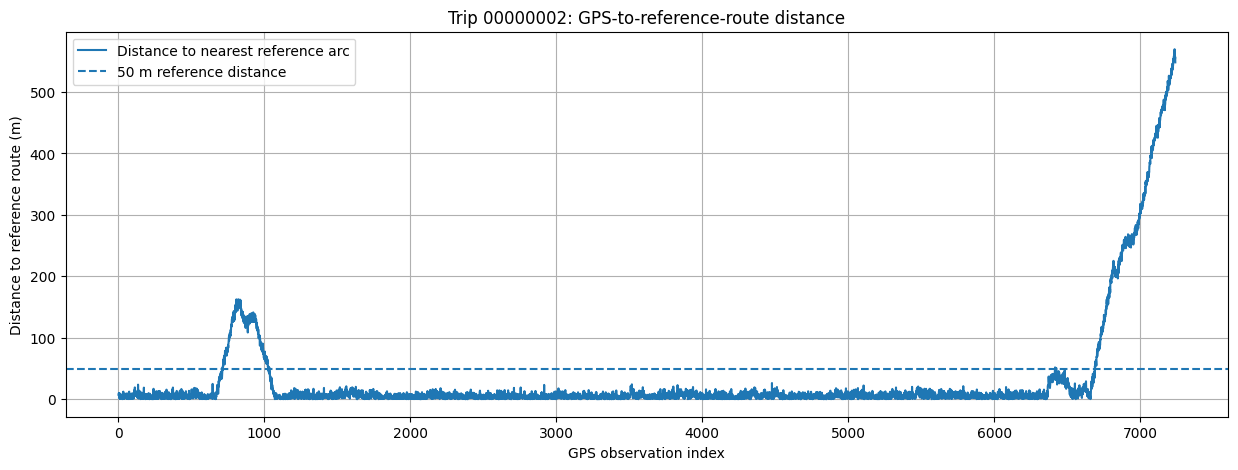

In [48]:
# Step 45: Analyze continuous reference-route mismatch sections

import matplotlib.pyplot as plt

# Sort observations by GPS order
diagnosis = diagnostics_df.sort_values("gps_index").copy()

# Identify consecutive GPS observations with reference-arc misses
diagnosis["is_miss"] = ~diagnosis["reference_arc_found"]

diagnosis["section"] = (
    diagnosis["is_miss"] != diagnosis["is_miss"].shift()
).cumsum()

miss_sections = (
    diagnosis[diagnosis["is_miss"]]
    .groupby("section")
    .agg(
        start_gps_index=("gps_index", "min"),
        end_gps_index=("gps_index", "max"),
        missed_points=("gps_index", "count"),
        mean_reference_distance_m=("reference_distance_m", "mean"),
        max_reference_distance_m=("reference_distance_m", "max")
    )
    .sort_values("missed_points", ascending=False)
    .reset_index(drop=True)
)

print("Number of continuous mismatch sections:", len(miss_sections))
print("\nLargest mismatch sections:")
display(miss_sections.head(15))

# Plot reference-route distance over GPS sequence
plt.figure(figsize=(15, 5))

plt.plot(
    diagnosis["gps_index"],
    diagnosis["reference_distance_m"],
    label="Distance to nearest reference arc"
)

plt.axhline(
    50,
    linestyle="--",
    label="50 m reference distance"
)

plt.xlabel("GPS observation index")
plt.ylabel("Distance to reference route (m)")
plt.title("Trip 00000002: GPS-to-reference-route distance")
plt.legend()
plt.grid(True)
plt.show()

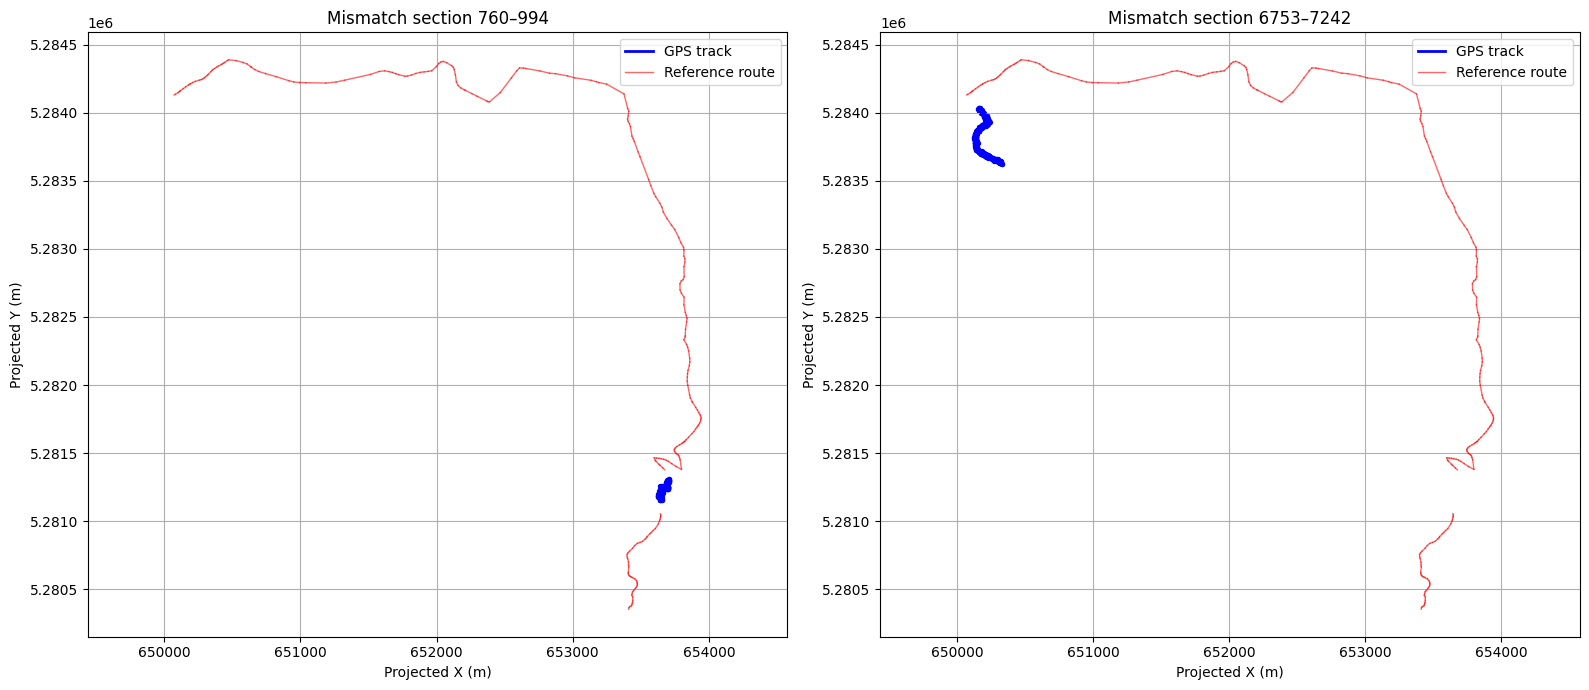

In [49]:
# Step 45: Spatial visualization of mismatch sections

import matplotlib.pyplot as plt
from shapely.geometry import LineString

trip_id = "00000002"

data = projected_data["train"][trip_id]
track = data["track"]

# Use the reconstructed reference-route geometries
# from the previous diagnostic cell:
# route_geometries

mismatch_sections = [
    (760, 994, "Mismatch section 760–994"),
    (6753, 7242, "Mismatch section 6753–7242")
]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (start, end, title) in zip(axes, mismatch_sections):

    gps_section = track.iloc[start:end + 1]

    # Plot GPS observations
    ax.plot(
        gps_section["x"],
        gps_section["y"],
        color="blue",
        linewidth=2,
        label="GPS track"
    )

    ax.scatter(
        gps_section["x"],
        gps_section["y"],
        color="blue",
        s=8
    )

    # Plot reference route segments
    for i, segment in enumerate(route_geometries):
        x, y = segment.xy
        ax.plot(
            x, y,
            color="red",
            linewidth=1,
            alpha=0.6,
            label="Reference route" if i == 0 else None
        )

    ax.set_title(title)
    ax.set_xlabel("Projected X (m)")
    ax.set_ylabel("Projected Y (m)")
    ax.legend()
    ax.grid(True)
    ax.set_aspect("equal", adjustable="datalim")

plt.tight_layout()
plt.show()

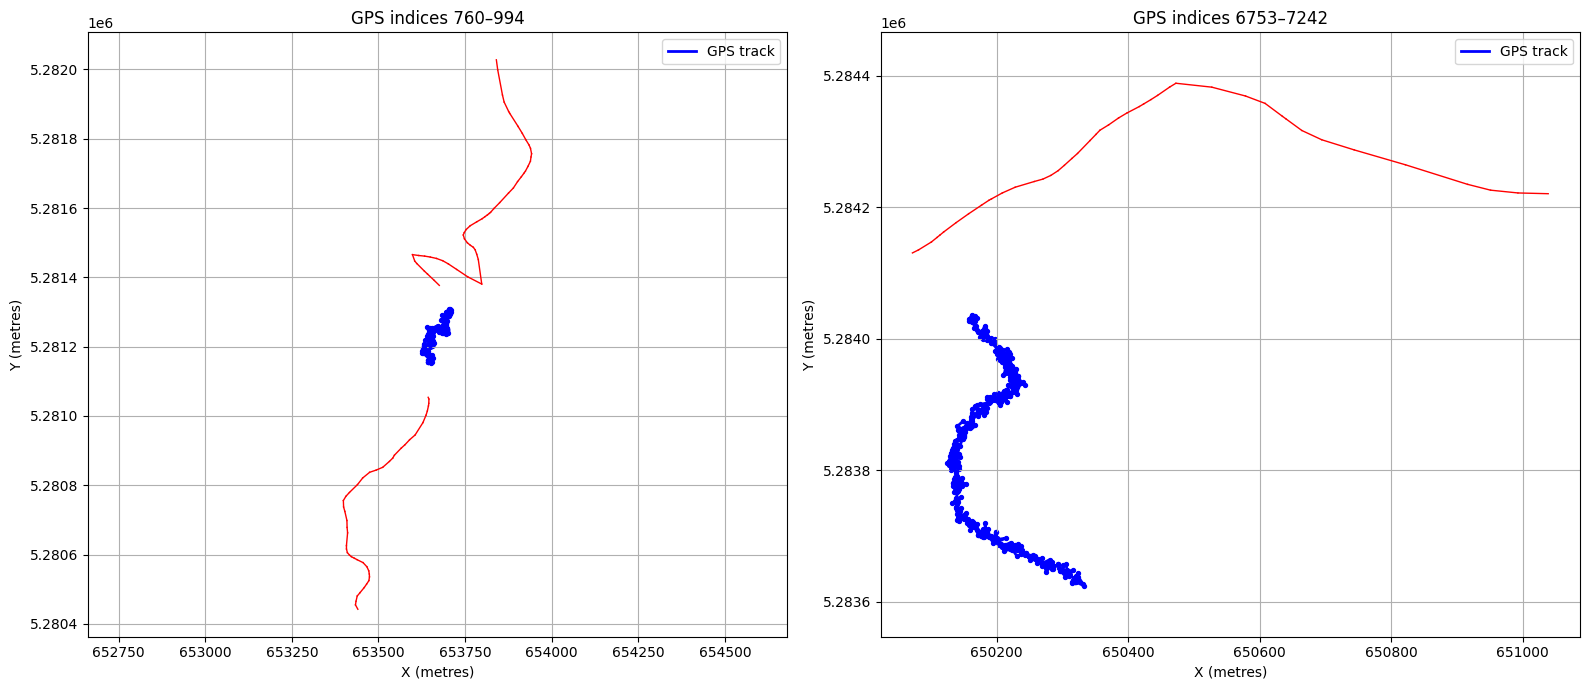

In [50]:
import matplotlib.pyplot as plt
from shapely.geometry import box

trip_id = "00000002"
track = projected_data["train"][trip_id]["track"]

mismatch_sections = [
    (760, 994, "GPS indices 760–994"),
    (6753, 7242, "GPS indices 6753–7242")
]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (start, end, title) in zip(axes, mismatch_sections):

    gps_section = track.iloc[start:end + 1]

    # GPS section boundaries, expanded by 700 metres
    minx, miny = gps_section["x"].min(), gps_section["y"].min()
    maxx, maxy = gps_section["x"].max(), gps_section["y"].max()

    search_area = box(
        minx - 700, miny - 700,
        maxx + 700, maxy + 700
    )

    # Plot only nearby reference-route segments
    for segment in route_geometries:
        if segment.intersects(search_area):
            x, y = segment.xy
            ax.plot(x, y, color="red", linewidth=1)

    # Plot GPS track
    ax.plot(
        gps_section["x"],
        gps_section["y"],
        color="blue",
        linewidth=2,
        label="GPS track"
    )

    ax.scatter(
        gps_section["x"],
        gps_section["y"],
        color="blue",
        s=8
    )

    ax.set_title(title)
    ax.set_xlabel("X (metres)")
    ax.set_ylabel("Y (metres)")
    ax.grid(True)
    ax.legend()
    ax.set_aspect("equal", adjustable="datalim")

plt.tight_layout()
plt.show()

In [51]:
# Step 46: Validate reference-route sequence continuity

trip_id = "00000002"

data = projected_data["train"][trip_id]
arcs = data["arcs"]

route_ids = data["route"]["arc_id"].astype(int).tolist()

continuity_results = []

for i in range(len(route_ids) - 1):

    current_arc = route_ids[i]
    next_arc = route_ids[i + 1]

    current_end = int(arcs.iloc[current_arc]["to_node"])
    next_start = int(arcs.iloc[next_arc]["from_node"])

    continuity_results.append({
        "route_position": i,
        "current_arc_id": current_arc,
        "next_arc_id": next_arc,
        "current_end_node": current_end,
        "next_start_node": next_start,
        "is_connected": current_end == next_start
    })

continuity_df = pd.DataFrame(continuity_results)

connected = continuity_df["is_connected"].sum()
total_transitions = len(continuity_df)

print("Trip:", trip_id)
print("Route entries:", len(route_ids))
print("Consecutive arc transitions:", total_transitions)
print("Connected transitions:", connected)
print("Disconnected transitions:", total_transitions - connected)

if total_transitions:
    print(
        f"Route continuity: "
        f"{connected / total_transitions * 100:.2f}%"
    )

print("\nFirst 15 transitions:")
display(continuity_df.head(15))

print("\nFirst 15 disconnected transitions:")
display(
    continuity_df[~continuity_df["is_connected"]].head(15)
)

Trip: 00000002
Route entries: 262
Consecutive arc transitions: 261
Connected transitions: 260
Disconnected transitions: 1
Route continuity: 99.62%

First 15 transitions:


,route_position,current_arc_id,next_arc_id,current_end_node,next_start_node,is_connected
0,0,3850,3848,1814,1814,True
1,1,3848,3853,1816,1816,True
2,2,3853,10445,5083,5083,True
3,3,10445,3855,1817,1817,True
4,4,3855,1274,574,574,True
5,5,1274,10454,5088,5088,True
6,6,10454,1272,573,573,True
7,7,1272,9585,4667,4667,True
8,8,9585,10425,5073,5073,True
9,9,10425,3859,1819,1819,True



First 15 disconnected transitions:


,route_position,current_arc_id,next_arc_id,current_end_node,next_start_node,is_connected
53,53,1848,10863,5059,5289,False


,arc_id,from_node,to_node,start_x,start_y,end_x,end_y,length_m
0,1848,846,5059,653645.753957,5.281049e+06,653643.513932,5.281054e+06,5.632318
1,10863,5289,5290,653675.696951,5.281377e+06,653661.043302,5.281391e+06,20.547489


Distance between disconnected endpoints: 324.63 m


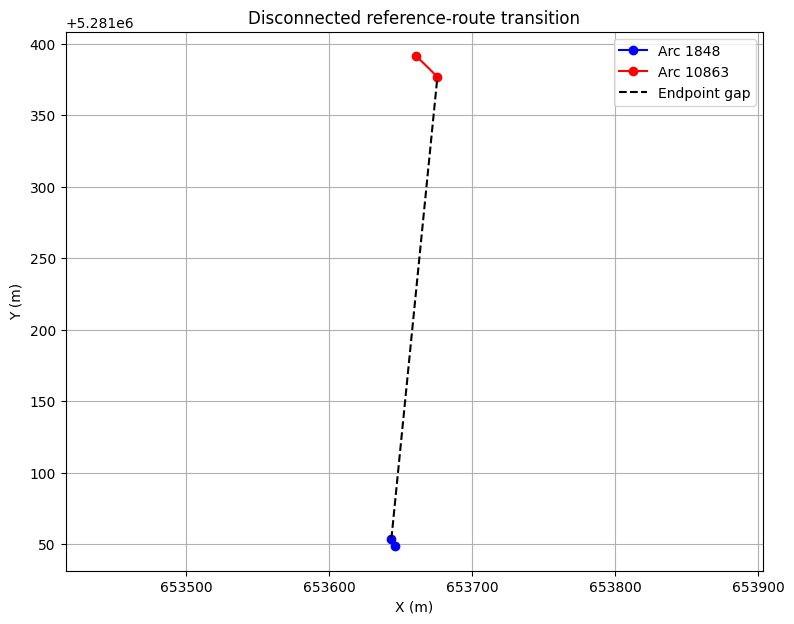

In [52]:
# Step 47: Inspect the disconnected reference-route transition

trip_id = "00000002"

data = projected_data["train"][trip_id]
nodes = data["nodes"]
arcs = data["arcs"]

current_arc_id = 1848
next_arc_id = 10863

def inspect_arc(arc_id):
    from_node = int(arcs.iloc[arc_id]["from_node"])
    to_node = int(arcs.iloc[arc_id]["to_node"])

    start = nodes.iloc[from_node]
    end = nodes.iloc[to_node]

    return {
        "arc_id": arc_id,
        "from_node": from_node,
        "to_node": to_node,
        "start_x": start["x"],
        "start_y": start["y"],
        "end_x": end["x"],
        "end_y": end["y"],
        "length_m": np.hypot(
            end["x"] - start["x"],
            end["y"] - start["y"]
        )
    }

current_info = inspect_arc(current_arc_id)
next_info = inspect_arc(next_arc_id)

display(pd.DataFrame([current_info, next_info]))

# Distance between the disconnected endpoints
gap_distance = np.hypot(
    current_info["end_x"] - next_info["start_x"],
    current_info["end_y"] - next_info["start_y"]
)

print(f"Distance between disconnected endpoints: {gap_distance:.2f} m")

# Plot the two arcs and their endpoints
plt.figure(figsize=(9, 7))

plt.plot(
    [current_info["start_x"], current_info["end_x"]],
    [current_info["start_y"], current_info["end_y"]],
    "bo-", label="Arc 1848"
)

plt.plot(
    [next_info["start_x"], next_info["end_x"]],
    [next_info["start_y"], next_info["end_y"]],
    "ro-", label="Arc 10863"
)

plt.plot(
    [current_info["end_x"], next_info["start_x"]],
    [current_info["end_y"], next_info["start_y"]],
    "k--", label="Endpoint gap"
)

plt.xlabel("X (m)")
plt.ylabel("Y (m)")
plt.title("Disconnected reference-route transition")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

In [53]:
# Step 48: Examine GPS observations around the route break

trip_id = "00000002"

track = projected_data["train"][trip_id]["track"]

# Display GPS observations around the first mismatch section
start_index = 730
end_index = 1030

gps_window = track.loc[start_index:end_index].copy()

# Add nearest-reference-arc labels from diagnostics
gps_window = gps_window.merge(
    diagnostics_df[
        ["gps_index", "reference_arc_id", "reference_distance_m"]
    ],
    left_index=True,
    right_on="gps_index",
    how="left"
)

print("GPS observations around the first mismatch section:")
display(gps_window[
    ["gps_index", "timestamp", "longitude", "latitude",
     "reference_arc_id", "reference_distance_m"]
].iloc[::10])

print("\nReference arc distribution:")
display(
    gps_window["reference_arc_id"].value_counts().head(15)
)

print("\nGPS observations assigned to arc 1848:")
display(
    gps_window[
        gps_window["reference_arc_id"] == 1848
    ][["gps_index", "timestamp", "reference_distance_m"]].head(20)
)

GPS observations around the first mismatch section:


,gps_index,timestamp,longitude,latitude,reference_arc_id,reference_distance_m
730,730,852.031,11.046832,47.665290,1848,78.758045
740,740,862.031,11.046702,47.665286,1848,75.796210
750,750,872.031,11.046831,47.665323,1848,82.223481
760,760,882.031,11.046659,47.665517,1848,100.654037
770,770,892.031,11.046541,47.665599,1848,109.102781
780,780,902.031,11.046559,47.665807,1848,132.257257
790,790,912.031,11.046360,47.665905,1848,143.463603
800,800,922.031,11.046463,47.665881,1848,140.437205
810,810,932.031,11.046776,47.666012,1848,156.353154
820,820,944.031,11.046656,47.666045,1848,159.073849



Reference arc distribution:


,count
reference_arc_id,
10863,207
1848,94



GPS observations assigned to arc 1848:


,gps_index,timestamp,reference_distance_m
730,730,852.031,78.758045
731,731,853.031,74.863484
732,732,854.031,75.307090
733,733,855.031,71.925442
734,734,856.031,72.515054
735,735,857.031,75.178464
736,736,858.031,77.150559
737,737,859.031,83.773079
738,738,860.031,76.353509
739,739,861.031,80.475474


In [54]:
# Step 49: Inspect the second major mismatch section

trip_id = "00000002"

track = projected_data["train"][trip_id]["track"]

start_index = 6740
end_index = 7242

gps_window = track.loc[start_index:end_index].copy()

gps_window = gps_window.merge(
    diagnostics_df[
        ["gps_index", "reference_arc_id", "reference_distance_m"]
    ],
    left_index=True,
    right_on="gps_index",
    how="left"
)

print("GPS observations in second mismatch section:")
display(
    gps_window[
        ["gps_index", "timestamp", "longitude", "latitude",
         "reference_arc_id", "reference_distance_m"]
    ].iloc[::20]
)

print("\nMost frequent reference arcs:")
display(gps_window["reference_arc_id"].value_counts().head(20))

print("\nReference distance statistics:")
display(gps_window["reference_distance_m"].describe())

print("\nFirst and last observations:")
display(pd.concat([gps_window.head(5), gps_window.tail(5)]))

GPS observations in second mismatch section:


,gps_index,timestamp,longitude,latitude,reference_arc_id,reference_distance_m
6740,6740,8346.141,11.001018,47.692290,341,116.910506
6760,6760,8366.156,11.001113,47.692169,341,132.124548
6780,6780,8386.156,11.001361,47.691971,341,160.501244
6800,6800,8408.156,11.001663,47.691710,341,196.970002
6820,6820,8435.156,11.001936,47.691537,341,223.909211
6840,6840,8496.156,11.001852,47.691674,341,207.619749
6860,6860,8521.156,11.001840,47.691488,341,224.985110
6880,6880,8541.156,11.001930,47.691349,341,241.742839
6900,6900,8561.156,11.002005,47.691324,341,246.968985
6920,6920,8581.156,11.001720,47.691099,588,258.168056



Most frequent reference arcs:


,count
reference_arc_id,
588,331
341,172



Reference distance statistics:


,reference_distance_m
count,503.000000
mean,325.745690
std,123.920515
min,108.687557
25%,229.765057
50%,290.662842
75%,438.733820
max,569.657738



First and last observations:


,longitude,latitude,timestamp,x,y,gps_index,reference_arc_id,reference_distance_m
6740,11.001018,47.692290,8346.141,650149.582382,5.284040e+06,6740,341,116.910506
6741,11.001004,47.692370,8347.141,650148.302189,5.284049e+06,6741,341,108.687557
6742,11.001029,47.692313,8348.141,650150.341708,5.284042e+06,6742,341,115.111552
6743,11.000976,47.692343,8349.141,650146.278776,5.284046e+06,6743,341,110.231896
6744,11.000943,47.692290,8350.141,650143.954850,5.284040e+06,6744,341,114.089480
7238,11.003176,47.688606,8924.156,650322.095048,5.283635e+06,7238,588,555.307164
7239,11.003296,47.688529,8925.156,650331.321080,5.283626e+06,7239,588,566.870189
7240,11.003204,47.688633,8926.156,650324.118530,5.283638e+06,7240,588,553.473705
7241,11.003133,47.688573,8928.156,650318.963224,5.283631e+06,7241,588,557.270873
7242,11.003208,47.688686,8934.156,650324.266337,5.283644e+06,7242,588,548.259429


Trip: 00000002
Total GPS observations: 7243


,Distance_Category,GPS_Observations,Percentage
0,0-10 m,5226,72.152423
1,10-25 m,961,13.267983
2,25-50 m,188,2.595610
3,50-100 m,149,2.057159
4,100-200 m,288,3.976253
5,Above 200 m,431,5.950573



Overall alignment statistics:


,reference_distance_m
count,7243.000000
mean,33.794166
std,89.470740
min,0.001070
25%,2.644151
50%,5.674005
75%,10.970344
max,569.657738


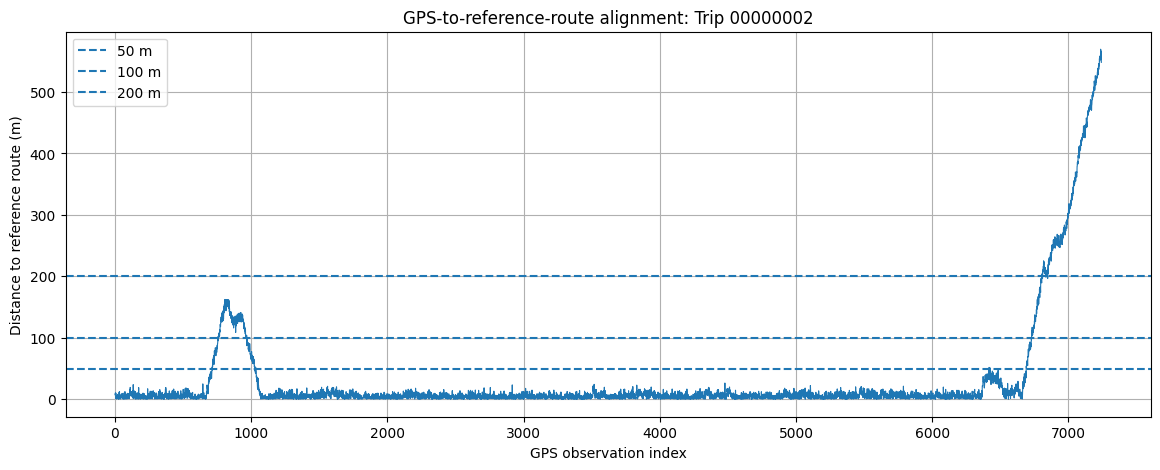

In [55]:
# Step 50: Classify GPS observations by reference-route distance

distance_df = diagnostics_df.copy()

distance_df["alignment_category"] = pd.cut(
    distance_df["reference_distance_m"],
    bins=[-1, 10, 25, 50, 100, 200, float("inf")],
    labels=[
        "0-10 m",
        "10-25 m",
        "25-50 m",
        "50-100 m",
        "100-200 m",
        "Above 200 m"
    ]
)

alignment_summary = (
    distance_df["alignment_category"]
    .value_counts(sort=False)
    .rename_axis("Distance_Category")
    .reset_index(name="GPS_Observations")
)

alignment_summary["Percentage"] = (
    alignment_summary["GPS_Observations"]
    / len(distance_df) * 100
)

print("Trip: 00000002")
print("Total GPS observations:", len(distance_df))

display(alignment_summary)

print("\nOverall alignment statistics:")
display(distance_df["reference_distance_m"].describe())

# Visualize alignment distance over time
plt.figure(figsize=(14, 5))

plt.plot(
    distance_df["gps_index"],
    distance_df["reference_distance_m"],
    linewidth=0.8
)

plt.axhline(50, linestyle="--", label="50 m")
plt.axhline(100, linestyle="--", label="100 m")
plt.axhline(200, linestyle="--", label="200 m")

plt.xlabel("GPS observation index")
plt.ylabel("Distance to reference route (m)")
plt.title("GPS-to-reference-route alignment: Trip 00000002")
plt.legend()
plt.grid(True)
plt.show()

In [56]:
# Step 51: Folium map for trip 00000001

import folium

trip_id = "00000001"

data = projected_data["train"][trip_id]
track = data["track"]
nodes = data["nodes"]
arcs = data["arcs"]

# Centre map on GPS observations
center_lat = track["latitude"].mean()
center_lon = track["longitude"].mean()

m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=14,
    tiles="OpenStreetMap"
)

# GPS track
gps_coordinates = list(
    zip(track["latitude"], track["longitude"])
)

folium.PolyLine(
    gps_coordinates,
    color="blue",
    weight=3,
    opacity=0.8,
    tooltip="GPS Track"
).add_to(m)

# GPS observation markers
gps_group = folium.FeatureGroup(
    name="GPS Observations"
)

for i, row in track.iterrows():
    if i % 10 == 0:
        folium.CircleMarker(
            location=[row["latitude"], row["longitude"]],
            radius=3,
            color="blue",
            fill=True,
            fill_opacity=0.7,
            tooltip=f"GPS Index: {i}"
        ).add_to(gps_group)

gps_group.add_to(m)

# Reference route
route_group = folium.FeatureGroup(
    name="Reference Route"
)

route_ids = data["route"]["arc_id"].astype(int).tolist()

for arc_id in route_ids:
    from_node = int(arcs.iloc[arc_id]["from_node"])
    to_node = int(arcs.iloc[arc_id]["to_node"])

    start = nodes.iloc[from_node]
    end = nodes.iloc[to_node]

    folium.PolyLine(
        [
            [start["latitude"], start["longitude"]],
            [end["latitude"], end["longitude"]]
        ],
        color="red",
        weight=3,
        opacity=0.7
    ).add_to(route_group)

route_group.add_to(m)

folium.LayerControl().add_to(m)

# Save interactive map
map_path = "/content/PathSnap_PersonA_Outputs/trip_00000001_map.html"

m.save(map_path)

print("Map saved:", map_path)

m

Map saved: /content/PathSnap_PersonA_Outputs/trip_00000001_map.html


In [57]:
# Step 52: Verify Person A output files

import os

output_dir = "/content/PathSnap_PersonA_Outputs"

for filename in sorted(os.listdir(output_dir)):
    filepath = os.path.join(output_dir, filename)

    print(
        filename,
        "|",
        round(os.path.getsize(filepath) / (1024 * 1024), 2),
        "MB"
    )

candidate_generation_summary.csv | 0.0 MB
student_test_candidate_features.parquet | 4.59 MB
train_candidate_features.parquet | 41.23 MB
trip_00000001_map.html | 0.38 MB


In [58]:
# Step 53: Package Person A deliverables

import shutil
import os

output_dir = "/content/PathSnap_PersonA_Outputs"
zip_path = "/content/PathSnap_PersonA_Final_Deliverables.zip"

shutil.make_archive(
    "/content/PathSnap_PersonA_Final_Deliverables",
    "zip",
    output_dir
)

print("ZIP created:", os.path.exists(zip_path))
print("ZIP size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

ZIP created: True
ZIP size: 38.92 MB


In [59]:
from google.colab import files

files.download("/content/PathSnap_PersonA_Final_Deliverables.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:
import pandas as pd

print("Available DataFrames:\n")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\nDataset: {name}")
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())
        display(obj.head(3))

Available DataFrames:


Dataset: train_inventory
Shape: (80, 9)
Columns: ['Trip_ID', 'NODES_Rows', 'NODES_Size_KB', 'TRACK_Rows', 'TRACK_Size_KB', 'ROUTE_Rows', 'ROUTE_Size_KB', 'ARCS_Rows', 'ARCS_Size_KB']


,Trip_ID,NODES_Rows,NODES_Size_KB,TRACK_Rows,TRACK_Size_KB,ROUTE_Rows,ROUTE_Size_KB,ARCS_Rows,ARCS_Size_KB
0,00000001,88809,1647.82,1315,40.01,525,3.05,165790,1902.81
1,00000002,7936,155.00,7243,232.50,262,1.37,16139,152.85
2,00000003,9138,178.48,821,25.55,79,0.40,18028,171.61



Dataset: test_inventory
Shape: (10, 9)
Columns: ['Trip_ID', 'NODES_Rows', 'NODES_Size_KB', 'TRACK_Rows', 'TRACK_Size_KB', 'ROUTE_Rows', 'ROUTE_Size_KB', 'ARCS_Rows', 'ARCS_Size_KB']


,Trip_ID,NODES_Rows,NODES_Size_KB,TRACK_Rows,TRACK_Size_KB,ROUTE_Rows,ROUTE_Size_KB,ARCS_Rows,ARCS_Size_KB
0,00000000,8542,166.84,2503,79.58,179,0.86,18196,172.84
1,00000007,2061,40.25,1354,42.55,123,0.47,4369,38.08
2,00000009,6745,131.74,1049,32.73,429,2.17,13106,123.72



Dataset: train_quality
Shape: (80, 7)
Columns: ['Trip_ID', 'Total_Points', 'Missing_Values', 'Invalid_Longitude', 'Invalid_Latitude', 'Zero_Coordinates', 'Duplicate_Points']


,Trip_ID,Total_Points,Missing_Values,Invalid_Longitude,Invalid_Latitude,Zero_Coordinates,Duplicate_Points
0,00000001,1315,0,0,0,0,0
1,00000002,7243,0,0,0,0,0
2,00000003,821,0,0,0,0,0


... (114 outputs left out)


Dataset: distance_df
Shape: (7243, 8)
Columns: ['gps_index', 'reference_arc_id', 'reference_distance_m', 'reference_arc_found', 'candidate_count', 'nearest_candidate_distance_m', 'search_radius_m', 'alignment_category']


,gps_index,reference_arc_id,reference_distance_m,reference_arc_found,candidate_count,nearest_candidate_distance_m,search_radius_m,alignment_category
0,0,3848,7.290634,True,48.0,7.290634,50.0,0-10 m
1,1,3850,9.045264,True,48.0,1.649546,50.0,0-10 m
2,2,3848,9.129673,True,48.0,4.389443,50.0,0-10 m



Dataset: alignment_summary
Shape: (6, 3)
Columns: ['Distance_Category', 'GPS_Observations', 'Percentage']


,Distance_Category,GPS_Observations,Percentage
0,0-10 m,5226,72.152423
1,10-25 m,961,13.267983
2,25-50 m,188,2.595610


In [62]:
print("Training partitions:")

print(candidate_features.keys())

for trip_id, df in list(candidate_features["train"].items())[:2]:
    print("\nTrip:", trip_id)
    print("Columns:", df.columns.tolist())
    display(df.head())

Training partitions:
dict_keys(['train', 'student_test'])

Trip: 00000001
Columns: ['gps_index', 'timestamp', 'arc_id', 'distance_m', 'search_radius_m', 'gps_speed_mps', 'gps_heading_deg', 'speed_quality', 'segment_length_m', 'segment_heading_deg', 'heading_difference_deg', 'Trip_ID', 'Partition']


,gps_index,timestamp,arc_id,distance_m,search_radius_m,gps_speed_mps,gps_heading_deg,speed_quality,segment_length_m,segment_heading_deg,heading_difference_deg,Trip_ID,Partition
0,0,1.0,2641,32.198445,50,NaN,NaN,missing,425.050298,7.491094,NaN,00000001,train
1,0,1.0,117639,15.132321,50,NaN,NaN,missing,1020.438110,187.689387,NaN,00000001,train
2,0,1.0,64973,0.722768,50,NaN,NaN,missing,293.237939,7.620028,NaN,00000001,train
3,1,2.0,117639,16.079744,50,43.632247,8.933595,normal,1020.438110,187.689387,178.755792,00000001,train
4,1,2.0,64973,0.277461,50,43.632247,8.933595,normal,293.237939,7.620028,1.313567,00000001,train



Trip: 00000002
Columns: ['gps_index', 'timestamp', 'arc_id', 'distance_m', 'search_radius_m', 'gps_speed_mps', 'gps_heading_deg', 'speed_quality', 'segment_length_m', 'segment_heading_deg', 'heading_difference_deg', 'Trip_ID', 'Partition']


,gps_index,timestamp,arc_id,distance_m,search_radius_m,gps_speed_mps,gps_heading_deg,speed_quality,segment_length_m,segment_heading_deg,heading_difference_deg,Trip_ID,Partition
0,0,1.0,1280,38.982247,50,NaN,NaN,missing,80.239161,189.279280,NaN,00000002,train
1,0,1.0,3813,38.982247,50,NaN,NaN,missing,80.239161,9.279280,NaN,00000002,train
2,0,1.0,3847,49.615181,50,NaN,NaN,missing,6.785522,301.218020,NaN,00000002,train
3,0,1.0,3691,49.615181,50,NaN,NaN,missing,6.785522,121.218020,NaN,00000002,train
4,0,1.0,3845,45.615887,50,NaN,NaN,missing,7.953888,343.157907,NaN,00000002,train


In [63]:
keywords = ["reference", "route", "truth", "ground", "label"]

for name, obj in globals().copy().items():
    if any(word in name.lower() for word in keywords):
        print(name, type(obj))

route <class 'pandas.core.frame.DataFrame'>
invalid_route_ids <class 'pandas.core.series.Series'>
route_ids <class 'list'>
route_geometries <class 'list'>
reference_route <class 'shapely.geometry.multilinestring.MultiLineString'>
gps_to_route_distances <class 'list'>
route_segments <class 'list'>
reference_labels <class 'list'>
reference_df <class 'pandas.core.frame.DataFrame'>
route_arc_ids <class 'list'>
reference_arc_id <class 'int'>
reference_distance <class 'float'>
route_group <class 'folium.map.FeatureGroup'>


In [64]:
print("candidate_features type:", type(candidate_features))
print("Partitions:", candidate_features.keys())

print("\nReference DataFrame:")
display(reference_df.head(10))

print("\nRoute DataFrame:")
display(route.head(10))

candidate_features type: <class 'dict'>
Partitions: dict_keys(['train', 'student_test'])

Reference DataFrame:


,gps_index,reference_arc_id,reference_distance_m,reference_arc_found
0,0,64973,0.722768,True
1,1,64973,0.277461,True
2,2,64973,1.839765,True
3,3,64973,6.147324,True
4,4,64973,2.652252,True
5,5,64973,5.529618,True
6,6,133948,2.427548,True
7,7,133949,3.467619,True
8,8,139208,0.630973,True
9,9,139208,5.812021,True



Route DataFrame:


,arc_id
0,2641
1,64973
2,133948
3,133949
4,139208
5,133950
6,8970
7,133951
8,64139
9,139211


In [65]:
print("Variables containing route/reference:")

for name, obj in globals().copy().items():
    if any(word in name.lower() for word in ["route", "reference"]):
        print(name, type(obj))

Variables containing route/reference:
route <class 'pandas.core.frame.DataFrame'>
invalid_route_ids <class 'pandas.core.series.Series'>
route_ids <class 'list'>
route_geometries <class 'list'>
reference_route <class 'shapely.geometry.multilinestring.MultiLineString'>
gps_to_route_distances <class 'list'>
route_segments <class 'list'>
reference_labels <class 'list'>
reference_df <class 'pandas.core.frame.DataFrame'>
route_arc_ids <class 'list'>
reference_arc_id <class 'int'>
reference_distance <class 'float'>
route_group <class 'folium.map.FeatureGroup'>


In [66]:
trip_candidates = candidate_features["train"]["00000001"]

reference_map = reference_df.set_index("gps_index")["reference_arc_id"]

trip_candidates["reference_arc_id"] = (
    trip_candidates["gps_index"].map(reference_map)
)

trip_candidates["Label"] = (
    trip_candidates["arc_id"] ==
    trip_candidates["reference_arc_id"]
).astype(int)

print("Label distribution:")
print(trip_candidates["Label"].value_counts())

display(
    trip_candidates[
        ["gps_index", "arc_id", "reference_arc_id", "Label"]
    ].head(15)
)

Label distribution:
Label
0    14649
1     1315
Name: count, dtype: int64


,gps_index,arc_id,reference_arc_id,Label
0,0,2641,64973,0
1,0,117639,64973,0
2,0,64973,64973,1
3,1,117639,64973,0
4,1,64973,64973,1
5,2,117639,64973,0
6,2,64973,64973,1
7,3,117639,64973,0
8,3,64973,64973,1
9,4,117639,64973,0


In [67]:
print("Number of route arc IDs:", len(route_arc_ids))
print("Number of reference labels:", len(reference_labels))
print("Number of route geometries:", len(route_geometries))
print("Number of GPS-to-route distances:", len(gps_to_route_distances))

print("\nFirst 15 route arc IDs:")
print(route_arc_ids[:15])

print("\nFirst 15 reference labels:")
print(reference_labels[:15])

print("\nFirst 15 GPS-to-route distances:")
print(gps_to_route_distances[:15])

print("\nReference DataFrame:")
print(reference_df.shape)
print(reference_df.columns.tolist())
display(reference_df.head())

Number of route arc IDs: 262
Number of reference labels: 1315
Number of route geometries: 262
Number of GPS-to-route distances: 1315

First 15 route arc IDs:
[3850, 3848, 3853, 10445, 3855, 1274, 10454, 1272, 9585, 10425, 3859, 1270, 3882, 3884, 3861]

First 15 reference labels:
[{'gps_index': 0, 'reference_arc_id': 64973, 'reference_distance_m': 0.7227677835356507}, {'gps_index': 1, 'reference_arc_id': 64973, 'reference_distance_m': 0.2774606701296314}, {'gps_index': 2, 'reference_arc_id': 64973, 'reference_distance_m': 1.8397646806228274}, {'gps_index': 3, 'reference_arc_id': 64973, 'reference_distance_m': 6.147324158370085}, {'gps_index': 4, 'reference_arc_id': 64973, 'reference_distance_m': 2.652251753258522}, {'gps_index': 5, 'reference_arc_id': 64973, 'reference_distance_m': 5.529617586481005}, {'gps_index': 6, 'reference_arc_id': 133948, 'reference_distance_m': 2.427547521693892}, {'gps_index': 7, 'reference_arc_id': 133949, 'reference_distance_m': 3.467618629896866}, {'gps_inde

,gps_index,reference_arc_id,reference_distance_m,reference_arc_found
0,0,64973,0.722768,True
1,1,64973,0.277461,True
2,2,64973,1.839765,True
3,3,64973,6.147324,True
4,4,64973,2.652252,True


In [68]:
print("Training trips:", len(candidate_features["train"]))

print("\nReference-related variables:")
for name, obj in globals().copy().items():
    if "reference" in name.lower() or "label" in name.lower():
        if isinstance(obj, (list, dict, pd.DataFrame)):
            print(
                name,
                type(obj),
                "Length/shape:",
                len(obj) if not isinstance(obj, pd.DataFrame)
                else obj.shape
            )

Training trips: 80

Reference-related variables:
reference_labels <class 'list'> Length/shape: 1315
reference_df <class 'pandas.core.frame.DataFrame'> Length/shape: (1315, 4)


In [69]:
print("Training candidate trips:", len(candidate_features["train"]))

for trip_id in list(candidate_features["train"].keys())[:10]:
    df = candidate_features["train"][trip_id]

    print(
        trip_id,
        "| GPS points:", df["gps_index"].nunique(),
        "| Candidate rows:", len(df)
    )

print("\nCurrent reference labels:", len(reference_df))

Training candidate trips: 80
00000001 | GPS points: 1315 | Candidate rows: 15964
00000002 | GPS points: 7013 | Candidate rows: 88192
00000003 | GPS points: 821 | Candidate rows: 20045
00000004 | GPS points: 1064 | Candidate rows: 8028
00000005 | GPS points: 1045 | Candidate rows: 3132
00000006 | GPS points: 1450 | Candidate rows: 16421
00000008 | GPS points: 3093 | Candidate rows: 40620
00000010 | GPS points: 2711 | Candidate rows: 49135
00000011 | GPS points: 2828 | Candidate rows: 17865
00000012 | GPS points: 1608 | Candidate rows: 6466

Current reference labels: 1315


In [70]:

from shapely.geometry import Point, LineString
import pandas as pd

# Store reference labels separately for every training trip
reference_labels_by_trip = {}
reference_dfs = {}
labeled_candidates_by_trip = {}

for trip_id, data in projected_data["train"].items():

    trip_id = str(trip_id)

    print(f"Processing trip {trip_id}...")

    # Get this trip's data
    nodes = data["nodes"]
    arcs = data["arcs"]
    track = data["track"]

    route_ids = data["route"]["arc_id"].astype(int).tolist()

    # Reconstruct this trip's reference-route segments
    route_segments = []

    for arc_id in route_ids:

        # Same indexing convention as your original code
        if arc_id < 0 or arc_id >= len(arcs):
            raise ValueError(
                f"Invalid arc ID {arc_id} in trip {trip_id}"
            )

        from_node = int(arcs.iloc[arc_id]["from_node"])
        to_node = int(arcs.iloc[arc_id]["to_node"])

        x1, y1 = nodes.iloc[from_node][["x", "y"]]
        x2, y2 = nodes.iloc[to_node][["x", "y"]]

        segment = LineString([(x1, y1), (x2, y2)])

        route_segments.append((arc_id, segment))

    if not route_segments:
        raise ValueError(f"No route segments found for trip {trip_id}")

    # Find the nearest reference-route arc for every GPS point
    trip_reference_labels = []

    for _, gps in track.iterrows():

        point = Point(gps["x"], gps["y"])

        nearest_arc_id, nearest_segment = min(
            route_segments,
            key=lambda item: item[1].distance(point)
        )

        nearest_distance = nearest_segment.distance(point)

        trip_reference_labels.append({
            "Trip_ID": trip_id,
            "gps_index": gps.name,
            "reference_arc_id": nearest_arc_id,
            "reference_distance_m": nearest_distance
        })

    # Create reference DataFrame for this trip
    trip_reference_df = pd.DataFrame(trip_reference_labels)

    # Get this trip's candidate features
    candidates = candidate_features["train"][trip_id].copy()

    # Check whether each reference arc exists in the candidate set
    candidate_arc_sets = (
        candidates.groupby("gps_index")["arc_id"]
        .apply(set)
        .to_dict()
    )

    trip_reference_df["reference_arc_found"] = (
        trip_reference_df.apply(
            lambda row: row["reference_arc_id"] in
            candidate_arc_sets.get(row["gps_index"], set()),
            axis=1
        )
    )

    # Generate labels for the candidate rows
    reference_map = trip_reference_df.set_index(
        "gps_index"
    )["reference_arc_id"]

    candidates["reference_arc_id"] = candidates["gps_index"].map(
        reference_map
    )

    candidates["Label"] = (
        candidates["arc_id"] == candidates["reference_arc_id"]
    ).astype(int)

    # Save results for this trip
    reference_labels_by_trip[trip_id] = trip_reference_labels
    reference_dfs[trip_id] = trip_reference_df
    labeled_candidates_by_trip[trip_id] = candidates

# Combine all trips into one reference DataFrame
reference_df_all = pd.concat(
    reference_dfs.values(),
    ignore_index=True
)

# Combine all labeled candidate rows
train_candidates_labeled = pd.concat(
    labeled_candidates_by_trip.values(),
    ignore_index=True
)

# Summary
print("\n========== TRAINING LABEL GENERATION SUMMARY ==========")

print("Number of training trips:", len(reference_dfs))
print("Total reference GPS labels:", len(reference_df_all))
print("Total candidate rows:", len(train_candidates_labeled))

print("\nLabel distribution:")
print(train_candidates_labeled["Label"].value_counts())

print("\nLabel percentages:")
print(
    train_candidates_labeled["Label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nCandidate recall across all training trips:")
print(
    reference_df_all["reference_arc_found"]
    .mean() * 100
)

print("\nReference labels by trip:")
display(
    reference_df_all.groupby("Trip_ID").agg(
        GPS_Points=("gps_index", "count"),
        Reference_Arcs_Found=("reference_arc_found", "sum")
    ).head(10)
)

print("\nFirst 10 labeled candidates:")
display(
    train_candidates_labeled[
        [
            "Trip_ID",
            "gps_index",
            "arc_id",
            "reference_arc_id",
            "Label"
        ]
    ].head(10)
)


Processing trip 00000001...
Processing trip 00000002...
Processing trip 00000003...
Processing trip 00000004...
Processing trip 00000005...
Processing trip 00000006...
Processing trip 00000008...
Processing trip 00000010...
Processing trip 00000011...
Processing trip 00000012...
Processing trip 00000013...
Processing trip 00000014...
Processing trip 00000016...
Processing trip 00000018...
Processing trip 00000019...
Processing trip 00000020...
Processing trip 00000021...
Processing trip 00000022...
Processing trip 00000024...
Processing trip 00000025...
Processing trip 00000026...
Processing trip 00000027...
Processing trip 00000028...
Processing trip 00000029...
Processing trip 00000031...
Processing trip 00000032...
Processing trip 00000033...
Processing trip 00000034...
Processing trip 00000035...
Processing trip 00000036...
Processing trip 00000037...
Processing trip 00000038...
Processing trip 00000039...
Processing trip 00000041...
Processing trip 00000042...
Processing trip 0000

,GPS_Points,Reference_Arcs_Found
Trip_ID,,
00000001,1315,1315
00000002,7243,6472
00000003,821,821
00000004,1064,1064
00000005,1045,1045
00000006,1450,1450
00000008,3093,3072
00000010,2711,2711
00000011,2828,2828



First 10 labeled candidates:


,Trip_ID,gps_index,arc_id,reference_arc_id,Label
0,00000001,0,2641,64973,0
1,00000001,0,117639,64973,0
2,00000001,0,64973,64973,1
3,00000001,1,117639,64973,0
4,00000001,1,64973,64973,1
5,00000001,2,117639,64973,0
6,00000001,2,64973,64973,1
7,00000001,3,117639,64973,0
8,00000001,3,64973,64973,1
9,00000001,4,117639,64973,0


In [71]:
# 1. Confirm all 80 trips were processed
print(len(labeled_candidates_by_trip))

# 2. Confirm every candidate has a label
print(train_candidates_labeled["Label"].isna().sum())

# 3. Check labels for one trip
display(
    labeled_candidates_by_trip["00000001"][
        ["gps_index", "arc_id", "reference_arc_id", "Label"]
    ].head(15)
)

80
0


,gps_index,arc_id,reference_arc_id,Label
0,0,2641,64973,0
1,0,117639,64973,0
2,0,64973,64973,1
3,1,117639,64973,0
4,1,64973,64973,1
5,2,117639,64973,0
6,2,64973,64973,1
7,3,117639,64973,0
8,3,64973,64973,1
9,4,117639,64973,0


In [72]:
# Save the complete labelled training dataset
output_file = "labelled_training_data.parquet"

train_candidates_labeled.to_parquet(
    output_file,
    index=False,
    engine="pyarrow"
)

print("File saved successfully:", output_file)
print("Dataset shape:", train_candidates_labeled.shape)
print("Columns:", train_candidates_labeled.columns.tolist())

File saved successfully: labelled_training_data.parquet
Dataset shape: (1944875, 15)
Columns: ['gps_index', 'timestamp', 'arc_id', 'distance_m', 'search_radius_m', 'gps_speed_mps', 'gps_heading_deg', 'speed_quality', 'segment_length_m', 'segment_heading_deg', 'heading_difference_deg', 'Trip_ID', 'Partition', 'reference_arc_id', 'Label']


In [73]:
from google.colab import files
files.download("labelled_training_data.parquet")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>